# Statistical analysis of four dimuon resonances in CMS Open Data: $J/\psi$, $\psi(2S)$, $\Upsilon(1S)$ and $Z$
Name: Aditya Kumar Choubey
Course: Statistical Inference for High Energy Physics (course project)
Data: CMS Open Data, 2016 DoubleMuon Run G, NanoAOD, $\sqrt{s} = 13$ TeV

---

## 1. Objective

With a loose muon selection the dimuon spectrum shows several resonances at once, spread over almost two orders of magnitude in mass. This notebook runs the same set of statistical tests on four of them.

| particle | PDG mass [GeV] | natural width | what shapes the peak |
|---|---|---|---|
| $J/\psi$ | 3.0969 | 93 keV | detector resolution + FSR tail (Crystal Ball) |
| $\psi(2S)$ | 3.6861 | 294 keV | detector resolution (tied to $J/\psi$) |
| $\Upsilon(1S)$ | 9.4603 | 54 keV | detector resolution + FSR tail (tied to $\Upsilon(2S)$, $\Upsilon(3S)$) |
| $Z$ | 91.1876 | 2.4952 GeV | Breit-Wigner $\otimes$ Crystal Ball (numerical convolution) |

The $\Upsilon(2S)$ and $\Upsilon(3S)$ are only 0.56 and 0.89 GeV above the $\Upsilon(1S)$, so they have to be in the model of that region or they bias the $\Upsilon(1S)$ fit. They are fitted and tested as well, and their splittings to the $\Upsilon(1S)$ are in Section 6.1, but the four particles above are the main results.

What is done:
1. Resolution in barrel vs endcap (Section 2.1), then a simultaneous fit of the BB / BE / EE muon-pair categories (Section 4).
2. Signal shape: Crystal Ball / double Crystal Ball for the narrow resonances, Breit-Wigner convolution for the $Z$. Whether the high-mass tail is needed is checked in Section 4c.
3. Extended unbinned likelihood fit with `iminuit` for yield, mass, resolution (and the width for the $Z$).
4. Discovery test, $H_0: N = 0$, with the likelihood ratio $q_0$.
5. Mass test, $H_0: m = m_{\text{PDG}}$, plus a profile-likelihood scan of the mass for each particle.
6. $\Upsilon$ mass splittings $\Delta m_{21}$, $\Delta m_{31}$, which are mostly insensitive to a common momentum-scale error.
7. $Z$ width test, $H_0: \Gamma = 2.4952$ GeV.
8. Likelihood contours and a 3D surface in the (mass, resolution) plane.
9. Binned fit as a cross-check, with a goodness-of-fit test.
10. Background model systematic (exponential vs exponential of a quadratic vs Bernstein polynomials).
11. Comparison of the relative mass offset across the four particles.

In [1]:
# pip install iminuit uproot awkward aiohttp fsspec
import os, time, hashlib
import numpy as np
import scipy.stats as stats
from scipy.signal import fftconvolve
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D   # noqa: needed for the 3D plot on older matplotlib
from iminuit import Minuit
import uproot
import awkward as ak

plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13, 'figure.dpi': 120})

# settings (make GRID_N smaller for a quick run)
GRID_N      = 9       # GRID_N x GRID_N fits per region
MASS_WINDOW = 0.015   # masses may move +-1.5 % around PDG

# model settings
ETA_SCHEME = '3cat'   # 'incl' | '2cat' (BB, rest) | '3cat' (BB, BE, EE)
ETA_EDGE   = 1.2      # |eta| boundary between muon barrel and endcap
USE_GCORE  = True     # add a narrow Gaussian core to the CB/DCB (peak is more peaked than a single CB core); region B overrides to False (low statistics)
USE_DCB    = True     # double-sided CB (False = single CB), Z region always uses False
DCB_NL     = 3.0      # fixed exponent of the low-mass tail
DCB_NR     = 3.0      # fixed exponent of the high-mass tail
BKG_ORDERS = (2, 3, 4)  # Bernstein orders for the bkg systematic, keep consecutive

PRETTY = {'J/psi': r'$J/\psi$', 'psi(2S)': r'$\psi(2S)$', 'Y(1S)': r'$\Upsilon(1S)$',
          'Y(2S)': r'$\Upsilon(2S)$', 'Y(3S)': r'$\Upsilon(3S)$', 'Z': r'$Z$'}

---
## 2. Data and event selection

* two opposite-charge muons (the two highest-$p_T$ muons in the event)
* $p_T > 3$ GeV for both
* $|\eta| < 2.4$
* no muon ID and no isolation, since these remove too many low-mass pairs

The DoubleMuon dataset is triggered for higher-mass pairs, so the low-mass region has fewer events than a dedicated quarkonium dataset would give. If the $\psi(2S)$ or $\Upsilon$ statistics are too low, add more files from the same folder to `FILES`. The masses and the two $|\eta|$ values are cached in a `.npy` file so the data only get streamed once.

In [2]:
# input files, add more if stats are too low
FILES = [
    'http://opendata.cern.ch/eos/opendata/cms/Run2016G/DoubleMuon/NANOAOD/UL2016_MiniAODv2_NanoAODv9-v2/2430000/4E3A26DE-E53B-A844-8048-36376617AE8D.root',
]
branches = ['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge']
CACHE = 'dimuon_v3_' + hashlib.md5(''.join(FILES).encode()).hexdigest()[:8] + '.npy'   # columns: m_mumu, |eta1|, |eta2|

def dimuon_from_file(url):
    with uproot.open(url) as f:
        ev = f['Events'].arrays(branches)
    n_events = len(ev)
    ev = ev[ev.nMuon >= 2]
    p1, p2 = ev.Muon_pt[:, 0], ev.Muon_pt[:, 1]
    eta1, eta2 = ev.Muon_eta[:, 0], ev.Muon_eta[:, 1]
    phi1, phi2 = ev.Muon_phi[:, 0], ev.Muon_phi[:, 1]
    mm1, mm2 = ev.Muon_mass[:, 0], ev.Muon_mass[:, 1]
    cut = ((ev.Muon_charge[:, 0] != ev.Muon_charge[:, 1]) &
           (p1 > 3.0) & (p2 > 3.0) & (np.abs(eta1) < 2.4) & (np.abs(eta2) < 2.4))
    px1, py1, pz1 = p1*np.cos(phi1), p1*np.sin(phi1), p1*np.sinh(eta1)
    px2, py2, pz2 = p2*np.cos(phi2), p2*np.sin(phi2), p2*np.sinh(eta2)
    E1 = np.sqrt(px1**2 + py1**2 + pz1**2 + mm1**2)
    E2 = np.sqrt(px2**2 + py2**2 + pz2**2 + mm2**2)
    m2_ = (E1+E2)**2 - (px1+px2)**2 - (py1+py2)**2 - (pz1+pz2)**2
    keep = lambda x: np.asarray(x[cut], dtype=np.float64)
    out = np.column_stack([keep(np.sqrt(np.maximum(m2_, 0))), keep(np.abs(eta1)), keep(np.abs(eta2))])
    return out, n_events

def assign_categories(a1, a2, scheme, edge=None):
    # category index per event and the category names
    edge = ETA_EDGE if edge is None else edge
    b1, b2 = a1 < edge, a2 < edge
    if scheme == 'incl':
        return np.zeros(len(a1), dtype=int), ['all']
    if scheme == '2cat':
        return np.where(b1 & b2, 0, 1), ['BB', 'BE+EE']
    if scheme == '3cat':
        return np.where(b1 & b2, 0, np.where(b1 | b2, 1, 2)), ['BB', 'BE', 'EE']
    raise ValueError(scheme)

if os.path.exists(CACHE):
    arr = np.load(CACHE)
    print(f"Loaded {len(arr)} dimuon pairs from the cache file {CACHE}")
else:
    print("Streaming data from CERN Open Data...")
    t0 = time.time()
    chunks, n_ev_total = [], 0
    for u in FILES:
        a_f, n_ev = dimuon_from_file(u)
        chunks.append(a_f); n_ev_total += n_ev
    arr = np.concatenate(chunks)
    arr = arr[np.isfinite(arr).all(axis=1) & (arr[:, 0] > 1.0) & (arr[:, 0] < 200.0)]
    np.save(CACHE, arr)
    print(f"Done in {time.time()-t0:.1f} s. {n_ev_total} events read, {len(arr)} dimuon pairs pass the loose selection.")

m_all, aeta1_all, aeta2_all = arr[:, 0], arr[:, 1], arr[:, 2]
cat_all, CAT_NAMES = assign_categories(aeta1_all, aeta2_all, ETA_SCHEME)
print("category fractions (" + ETA_SCHEME + "): " + ", ".join(f"{n} {np.mean(cat_all == c):.3f}" for c, n in enumerate(CAT_NAMES)))


Loaded 32403 dimuon pairs from the cache file dimuon_v3_ab47a935.npy
category fractions (3cat): BB 0.407, BE 0.348, EE 0.245


### 2.1 Detector geometry

The CMS momentum resolution $\sigma(p_T)/p_T$ depends a lot on $|\eta|$. In the barrel ($|\eta| < 1.2$) the muon crosses the tracker perpendicular to the 3.8 T field, with a long lever arm and little material. In the endcap ($|\eta| \ge 1.2$) the lever arm is shorter and there is more material, so more multiple scattering and bremsstrahlung.

A pair is called BB (both barrel), BE (one of each) or EE (both endcap). Below the three are compared in the $J/\psi$ and $Z$ windows, using half the central 68 % interval, $\tfrac12(q_{84}-q_{16})$, as the width. This does not depend on a model, but it still includes the background under the peak (and the natural width for the $Z$), so it is only a rough comparison. The fit in Section 4 separates these through the free resolution ratios $r_{BE}$, $r_{EE}$.

An inclusive sample mixes these resolutions, which gives the peak non-Gaussian tails. That is why the line shape has tail parameters (Section 3) and why the categories are fitted together.

$J/\psi$ region          half-68% width: BB = 36.5 MeV,  BE = 52.3 MeV,  EE = 62.8 MeV   (relative to BB: 1.00, 1.43, 1.72)
$Z$ region               half-68% width: BB = 3.1 GeV,  BE = 3.7 GeV,  EE = 4.0 GeV   (relative to BB: 1.00, 1.18, 1.28)


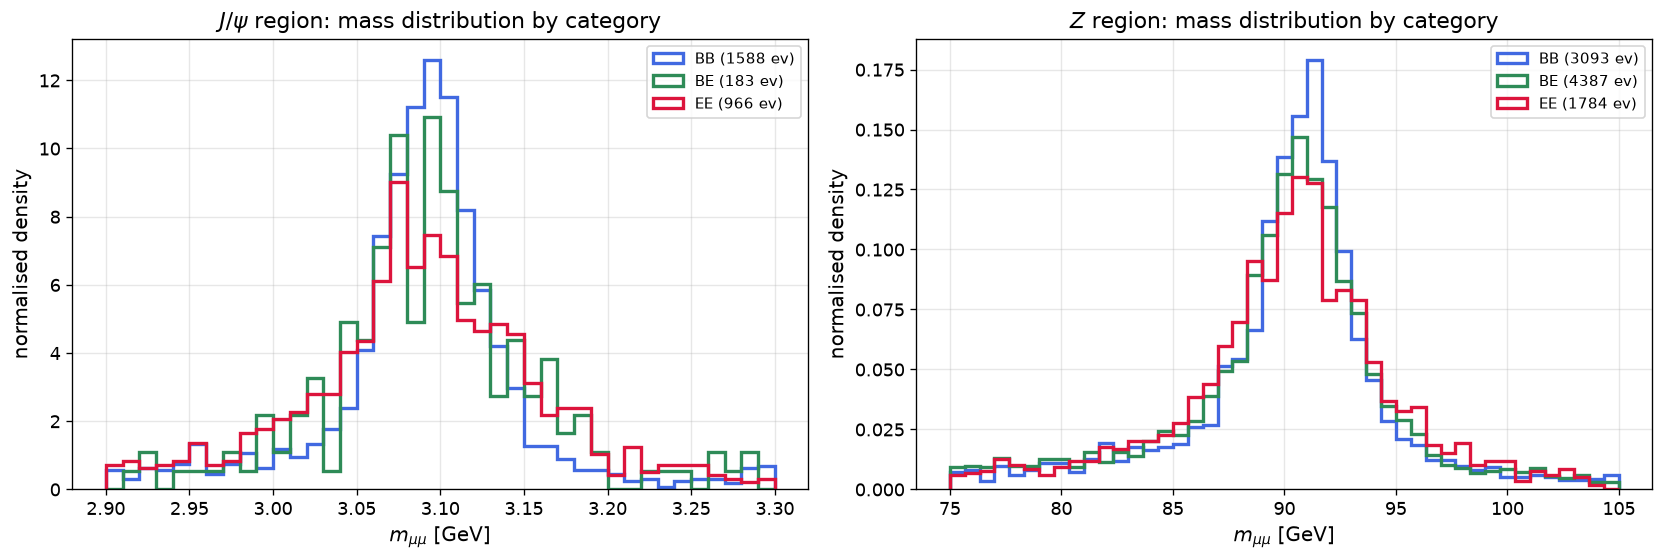

In [3]:
# compare BB / BE / EE directly (independent of ETA_SCHEME)
cat3, names3 = assign_categories(aeta1_all, aeta2_all, '3cat')
cols3 = ['royalblue', 'seagreen', 'crimson']
wins = [(r'$J/\psi$ region', 2.9, 3.3, 40, 1000.0, 'MeV'), (r'$Z$ region', 75.0, 105.0, 45, 1.0, 'GeV')]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (title, lo, hi, nb, scale, unit) in zip(axes, wins):
    sel = (m_all >= lo) & (m_all <= hi)
    widths = []
    for c, (nm, col) in enumerate(zip(names3, cols3)):
        x = m_all[sel & (cat3 == c)]
        widths.append(0.5*(np.percentile(x, 84) - np.percentile(x, 16)))
        ax.hist(x, bins=nb, range=(lo, hi), density=True, histtype='step', lw=2, color=col, label=f'{nm} ({len(x)} ev)')
    ax.set_title(title + ': mass distribution by category')
    ax.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); ax.set_ylabel('normalised density'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
    print(f"{title:<24} half-68% width: " + ",  ".join(f"{nm} = {scale*w:.1f} {unit}" for nm, w in zip(names3, widths))
          + "   (relative to BB: " + ", ".join(f"{w/widths[0]:.2f}" for w in widths) + ")")
plt.tight_layout(); plt.show()

---
## 3. The model

Three mass regions are fitted separately. In each one the model is a sum of signal peaks and a smooth background inside the window $[m_{\min}, m_{\max}]$.

| region | window [GeV] | peaks |
|---|---|---|
| A | 2.7 to 4.1 | $J/\psi$, $\psi(2S)$ |
| B | 8.6 to 11.4 | $\Upsilon(1S)$, $\Upsilon(2S)$, $\Upsilon(3S)$ |
| C | 70 to 110 | $Z$ |

Line shape. The observed peak is the true resonance shape folded with the detector resolution, and a Gaussian is not enough for that:
* final-state radiation: a muon can radiate a photon that is not in the reconstructed pair, so $m_{\mu\mu}$ comes out too low. This gives a tail towards low mass.
* energy loss and bremsstrahlung in the tracker material add to the same low-mass tail.
* badly measured tracks give outliers towards high mass.

So the resolution is a double Crystal Ball (DCB), a Gaussian core of width $\sigma$ with a power-law tail on each side. With $t = x/\sigma$ ($x$ measured from the peak position):
$$\text{DCB}(t) \propto \begin{cases} A_L\,(B_L - t)^{-n_L} & t < -\alpha_L \\ \exp(-t^2/2) & -\alpha_L \le t \le \alpha_R \\ A_R\,(B_R + t)^{-n_R} & t > \alpha_R \end{cases}, \qquad A_i = \Big(\frac{n_i}{\alpha_i}\Big)^{n_i} e^{-\alpha_i^2/2},\quad B_i = \frac{n_i}{\alpha_i} - \alpha_i$$
The exponents are fixed to $n_L = n_R = 3$ (`DCB_NL`, `DCB_NR`) and $\alpha_L$ (`alpha`), $\alpha_R$ (`alphaR`) are free. With `USE_DCB = False` the right tail is dropped and this becomes the single Crystal Ball.

Narrow core. Inside one $\eta$ category the resolution still differs from muon to muon ($p_T$, exact $\eta$), so the real core is more peaked than one Gaussian. A single CB then leaves the bins at the top of the peak above the fit and the shoulders below it. The resolution is therefore a mixture
$$(1 - f_g)\,\text{DCB}(\sigma) + f_g\,\text{Gauss}(r_g\,\sigma),$$
with free $f_g$ (`fg`) and $r_g < 1$ (`rg`), shared by all categories and peaks of a region (`USE_GCORE`). It is used in regions A and C. Region B has too few events and keeps the plain DCB. $\sigma$ is then the width of the CB component (the broad part of the core) and the narrow Gaussian has width $r_g\sigma$.

Natural width vs resolution. For the $J/\psi$, $\psi(2S)$ and $\Upsilon$ the natural widths (93, 294, 54 keV) are far below the resolution ($\sim 40$ to $50$ MeV at 3 GeV, $\sim 100$ MeV at 9.5 GeV), so the Breit-Wigner is effectively a delta function and the peak is just the DCB. For the $Z$ the shape is a Breit-Wigner convolved with the resolution, done numerically on a fine grid, with $\Gamma$ free. The Breit-Wigner already has heavy tails on both sides and $\alpha_R$ would be strongly correlated with $\Gamma$, so the $Z$ region uses the single CB by default (`dcb=False`). Section 4c checks this.

$\eta$ categories. Every pair goes into BB, BE or EE using $|\eta_1|, |\eta_2|$ with the boundary `ETA_EDGE` = 1.2, and all categories are fitted at the same time:
* masses $m_k$, yields $N_k$, $\alpha_L$, $\alpha_R$ and $\Gamma$ are shared,
* the resolution in category $c$ is $\sigma_{k,c} = \sigma\, r_c\, M_k/M_1$, where $\sigma$ is the BB resolution ($r_{BB}=1$) and $r_{BE}, r_{EE}$ (`r1`, `r2`) are free,
* the signal fraction in each category $f^s_c$ (`fs0`, `fs1`, shared by all peaks in a region) and the background fraction $f^b_c$ (`fb0`, `fb1`) are free, parametrised so they sum to 1,
* the background shape is the same in all categories.

Other parameters. Each peak has its own mass $m_k$, limited to $\pm 1.5\,\%$ around the PDG value $M_k$, so the mass offset is just $m_k - M_k$. Inside a region the resolution scales with mass, and the weak peaks ($\psi(2S)$, $\Upsilon(2S)$, $\Upsilon(3S)$) are tied to the first one. The background is an exponential, $B(m) \propto e^{-\lambda (m - m_{\min})}$, normalised in the window. Other shapes are tried in Section 9.

The likelihood is extended, with yields $N_k$, background yield $N_B$ and category $c_i$ of event $i$:
$$-\ln L = \Big(\sum_k N_k + N_B\Big) - \sum_{i=1}^{N}\ln\Big[\sum_k N_k\, f^s_{c_i} P_{k,c_i}(m_i) + N_B\, f^b_{c_i} B(m_i)\Big]$$
With `ETA_SCHEME = 'incl'` there is only one category and this reduces to the plain fit.

In [4]:
# line shapes and the Region class (data, model, fit)
from scipy.special import comb
GAMMA_Z_PDG = 2.4952

def dcb(x, sigma, alphaL, alphaR=None, nL=DCB_NL, nR=DCB_NR):
    # double-sided Crystal Ball centred at 0, not normalised. alphaR=None gives the single CB
    t = x / sigma
    AL = (nL/alphaL)**nL * np.exp(-alphaL**2/2)
    BL = nL/alphaL - alphaL
    out = np.exp(-0.5*t**2)
    lo = t < -alphaL
    out[lo] = AL * (BL - t[lo])**(-nL)
    if alphaR is not None:
        AR = (nR/alphaR)**nR * np.exp(-alphaR**2/2)
        BR = nR/alphaR - alphaR
        hi = t > alphaR
        out[hi] = AR * (BR + t[hi])**(-nR)
    return out

def crystal_ball(x, sigma, alpha):
    return dcb(x, sigma, alpha, None)

class Region:
    NSUB = 40      # fine grid points per histogram bin

    def __init__(self, name, lo, hi, nbins, peaks, masses, sig_guess,
                 use_bw=False, quad_bkg=False, mass_window=MASS_WINDOW,
                 bkg=None, bern_order=3, dcb=None, cat_scheme=None, gcore=None):
        self.name, self.lo, self.hi, self.nbins = name, lo, hi, nbins
        self.peaks, self.M = peaks, np.array(masses, dtype=float)
        self.K = len(peaks)
        self.sig_guess = sig_guess
        self.use_bw = use_bw                          # Breit-Wigner x resolution (only for the Z)
        self.bkg = bkg if bkg else ('exp2' if quad_bkg else 'exp')   # 'exp' | 'exp2' | 'bern'
        self.bern_order = bern_order
        self.dcb = USE_DCB if dcb is None else dcb    # double-sided tail on/off
        self.gcore = USE_GCORE if gcore is None else gcore   # narrow Gaussian core on top of the CB/DCB
        self.cat_scheme = ETA_SCHEME if cat_scheme is None else cat_scheme
        self.mw = mass_window
        sel = (m_all >= lo) & (m_all <= hi)
        self.data = m_all[sel]
        self.cat, self.catnames = assign_categories(aeta1_all[sel], aeta2_all[sel], self.cat_scheme)
        self.C = len(self.catnames)
        self.N = len(self.data)
        # fine grid used for the pdfs: nbins * NSUB cells
        self.ng = nbins*self.NSUB
        self.dx = (hi - lo)/self.ng
        self.xe = lo + self.dx*np.arange(self.ng + 1)
        self.xg = 0.5*(self.xe[:-1] + self.xe[1:])
        self.npad = int(0.3*self.ng)
        self.ext = lo - self.npad*self.dx + self.dx*(np.arange(self.ng + 2*self.npad) + 0.5)
        self.kx = self.dx*np.arange(-self.npad, self.npad + 1)
        # histograms: inclusive and per category
        self.counts, self.bin_edges = np.histogram(self.data, bins=nbins, range=(lo, hi))
        self.counts_c = np.array([np.histogram(self.data[self.cat == c], bins=nbins, range=(lo, hi))[0]
                                  for c in range(self.C)])
        self.bin_centers = 0.5*(self.bin_edges[:-1] + self.bin_edges[1:])
        self.bin_width = self.bin_edges[1] - self.bin_edges[0]
        # parameter names
        if self.bkg == 'exp':
            self.bkg_names = ['lam']
        elif self.bkg == 'exp2':
            self.bkg_names = ['lam', 'lam2']
        elif self.bkg == 'bern':
            self.bkg_names = [f'bk{j}' for j in range(1, bern_order + 1)]
        else:
            raise ValueError(self.bkg)
        self.names = ([f'n{k}' for k in range(self.K)] + ['nb'] +
                      [f'm{k}' for k in range(self.K)] + ['sig', 'alpha'] +
                      (['alphaR'] if self.dcb else []) + (['fg', 'rg'] if self.gcore else []) + self.bkg_names +
                      (['gam'] if use_bw else []) +
                      [f'r{c}' for c in range(1, self.C)] +
                      [f'fs{j}' for j in range(self.C - 1)] + [f'fb{j}' for j in range(self.C - 1)])
        # parameters that describe the signal shape (frozen in the null fit of a single-peak region)
        self.signal_shape_names = [n for n in self.names
                                   if n in ('sig', 'alpha', 'alphaR', 'gam', 'fg') or n.startswith(('r', 'fs'))]
        self.ndof = self.C*nbins - len(self.names)
        self._make_start()

    def _make_start(self):
        med = np.median(self.counts)/self.bin_width        # background per GeV
        st = {}
        n_sig = 0.0
        sg0 = self.sig_guess*(0.8 if self.C > 1 else 1.0)    # sig is the BB (best) resolution
        for k in range(self.K):
            sg = sg0*self.M[k]/self.M[0]
            c = np.sum(np.abs(self.data - self.M[k]) < 2.5*sg)
            st[f'n{k}'] = max(c - med*5*sg, 10.0)
            st[f'm{k}'] = self.M[k]
            n_sig += st[f'n{k}']
        st.update(nb=max(self.N - n_sig, 0.1*self.N), sig=sg0, alpha=1.5)
        if self.dcb:
            st['alphaR'] = 2.0
        if self.gcore:
            st['fg'], st['rg'] = 0.3, 0.5
        for n in self.bkg_names:
            st[n] = 0.0
        if self.use_bw:
            st['gam'] = GAMMA_Z_PDG
        for c in range(1, self.C):
            st[f'r{c}'] = 1.0 + 0.6*c
        frac = np.bincount(self.cat, minlength=self.C)/max(self.N, 1)
        rest = 1.0
        for j in range(self.C - 1):
            v = frac[j]/rest if rest > 1e-9 else 0.5
            v = min(max(v, 0.01), 0.99)
            st[f'fs{j}'] = v; st[f'fb{j}'] = v
            rest *= (1 - v)
        self.start = st

    # shapes on the fine grid
    @staticmethod
    def resolution(x, sig, alpha, alphaR=None, fg=None, rg=None):
        # unit-sum resolution function: (1 - fg) * (D)CB of width sig + fg * narrow Gaussian of width rg*sig
        f = dcb(x, sig, alpha, alphaR); f = f/f.sum()
        if fg is None:
            return f
        g = np.exp(-0.5*(x/(rg*sig))**2); g = g/g.sum()
        return (1 - fg)*f + fg*g

    def peak_shape(self, mass, sig, alpha, gam=None, alphaR=None, fg=None, rg=None):
        if self.use_bw:
            h = gam/2.0
            bw = h/((self.ext - mass)**2 + h**2)
            ker = self.resolution(self.kx, sig, alpha, alphaR, fg, rg)
            f = fftconvolve(bw, ker, mode='same')[self.npad:self.npad + self.ng]
        else:
            f = self.resolution(self.xg - mass, sig, alpha, alphaR, fg, rg)
        return f/(f.sum()*self.dx)

    def bkg_shape(self, p):
        t = self.xg - self.lo
        W = self.hi - self.lo
        if self.bkg == 'exp':
            f = np.exp(-p['lam']*t)
        elif self.bkg == 'exp2':
            f = np.exp(-p['lam']*t - p['lam2']*(t/W)**2)
        else:                                   # Bernstein polynomial, coefficients exp(a_j) > 0, a_0 = 0
            n, x = self.bern_order, t/W
            a = [0.0] + [p[f'bk{j}'] for j in range(1, n + 1)]
            f = sum(np.exp(a[j])*comb(n, j)*x**j*(1 - x)**(n - j) for j in range(n + 1))
        return f/(f.sum()*self.dx)

    @staticmethod
    def _stick(p, prefix, C):
        fr, rest = [], 1.0
        for j in range(C - 1):
            v = p[f'{prefix}{j}']
            fr.append(rest*v); rest *= (1 - v)
        fr.append(rest)
        return np.array(fr)

    def cat_components(self, p):
        # (yield, category fractions, normalised pdfs) for every peak, then the background
        fs = self._stick(p, 'fs', self.C); fb = self._stick(p, 'fb', self.C)
        r = np.array([1.0] + [p[f'r{c}'] for c in range(1, self.C)])
        out = []
        for k in range(self.K):
            sk = p['sig']*self.M[k]/self.M[0]
            pdf = np.array([self.peak_shape(p[f'm{k}'], sk*r[c], p['alpha'], p.get('gam'), p.get('alphaR'), p.get('fg'), p.get('rg'))
                            for c in range(self.C)])
            out.append((p[f'n{k}'], fs, pdf))
        out.append((p['nb'], fb, np.tile(self.bkg_shape(p), (self.C, 1))))
        return out

    def components(self, p):
        # (yield, pdf on grid) per component, summed over categories, for the plots
        return [(y, (fr[:, None]*pdf).sum(axis=0)) for y, fr, pdf in self.cat_components(p)]

    def density_cat(self, p):
        return sum(y*fr[:, None]*pdf for y, fr, pdf in self.cat_components(p))      # (C, ng)

    def density_grid(self, p):
        return self.density_cat(p).sum(axis=0)

    def expected_bins_cat(self, p):
        return (self.density_cat(p)*self.dx).reshape(self.C, self.nbins, self.NSUB).sum(axis=2)

    def expected_bins(self, p):
        return self.expected_bins_cat(p).sum(axis=0)

    def deviance(self, p):
        # Poisson deviance over all categories and bins
        mu, n = self.expected_bins_cat(p), self.counts_c
        nz = n > 0
        return 2*np.sum(mu - n) + 2*np.sum(n[nz]*np.log(n[nz]/mu[nz]))

    def deviance_incl(self, p):
        # Poisson deviance of the inclusive histogram
        mu, n = self.expected_bins(p), self.counts
        nz = n > 0
        return 2*np.sum(mu - n) + 2*np.sum(n[nz]*np.log(n[nz]/mu[nz]))

    # fitting
    def fit(self, fix=None, start=None, data=None, binned=False, minos=(), tie=None):
        # tie=(k, r, delta) imposes m_k = m_r + delta, used for the splitting profile
        dm, dc = (self.data, self.cat) if data is None else data
        dms = [dm[dc == c] for c in range(self.C)]
        cnt = np.array([np.histogram(x, bins=self.nbins, range=(self.lo, self.hi))[0] for x in dms])
        names = self.names
        def fcn(par):
            p = dict(zip(names, par))
            if tie is not None:
                p[f'm{tie[0]}'] = p[f'm{tie[1]}'] + tie[2]
            if p['sig'] < 1e-4 or p['alpha'] < 0.1 or p.get('alphaR', 1.0) < 0.1:
                return 1e12
            dens_c = self.density_cat(p)                       # (C, ng)
            ntot = sum(p[f'n{k}'] for k in range(self.K)) + p['nb']
            if binned:
                mu = (dens_c*self.dx).reshape(self.C, self.nbins, self.NSUB).sum(axis=2)
                if np.any(mu <= 0):
                    return 1e12
                return np.sum(mu - cnt*np.log(mu))
            nll = ntot
            for c in range(self.C):
                if len(dms[c]) == 0:
                    continue
                dens = np.interp(dms[c], self.xg, dens_c[c])
                if np.any(dens <= 0):
                    return 1e12
                nll -= np.sum(np.log(dens))
            return nll
        st = dict(self.start)
        if start:
            st.update({k: v for k, v in start.items() if k in st})
        if fix:
            st.update(fix)
        m = Minuit(fcn, np.array([st[k] for k in names]), name=names)
        N = len(dm)
        L = 12.0/(self.hi - self.lo)
        for k in range(self.K):
            m.limits[f'n{k}'] = (0, 3*N)
            m.limits[f'm{k}'] = (self.M[k]*(1 - self.mw), self.M[k]*(1 + self.mw))
        m.limits['nb'] = (0, 3*N)
        m.limits['sig'] = (0.25*self.sig_guess, 4*self.sig_guess)
        m.limits['alpha'] = (0.3, 5.0)
        if self.dcb:
            m.limits['alphaR'] = (0.3, 5.0)
        if self.gcore:
            m.limits['fg'] = (1e-3, 0.9)
            m.limits['rg'] = (0.2, 0.95)
        if 'lam' in names:
            m.limits['lam'] = (-L, L)
        if 'lam2' in names:
            m.limits['lam2'] = (-8.0, 8.0)
        for j in range(1, self.bern_order + 1):
            if f'bk{j}' in names:
                m.limits[f'bk{j}'] = (-10.0, 10.0)
        if self.use_bw:
            m.limits['gam'] = (0.8, 6.0)
        for c in range(1, self.C):
            m.limits[f'r{c}'] = (0.5, 6.0)
        for j in range(self.C - 1):
            m.limits[f'fs{j}'] = (1e-3, 1 - 1e-3)
            m.limits[f'fb{j}'] = (1e-3, 1 - 1e-3)
        m.errordef = Minuit.LIKELIHOOD
        if fix:
            for k in fix:
                m.fixed[k] = True
        if tie is not None:
            m.fixed[f'm{tie[0]}'] = True
        m.migrad()
        if not m.valid:
            m.migrad()
        m.hesse()
        for k in minos:
            try:
                m.minos(k)
            except Exception:
                pass
        return dict(values=m.values.to_dict(), errors=m.errors.to_dict(), fval=m.fval, valid=m.valid, m=m)

regions = {
    'A': Region('A: J/psi, psi(2S)', 2.7, 4.1, 56, ['J/psi', 'psi(2S)'], [3.0969, 3.6861], sig_guess=0.045),
    'B': Region('B: Upsilon family', 8.6, 11.4, 56, ['Y(1S)', 'Y(2S)', 'Y(3S)'], [9.4603, 10.0233, 10.3552], sig_guess=0.12, gcore=False),
    'C': Region('C: Z', 70.0, 110.0, 60, ['Z'], [91.1876], sig_guess=2.0, use_bw=True, dcb=False),
}
# the four main particles: (region key, index of the peak in that region)
MAIN = [('A', 0), ('A', 1), ('B', 0), ('C', 0)]

for key, R in regions.items():
    print(f"region {R.name:<22} window [{R.lo}, {R.hi}] GeV: {R.N} events, categories {R.catnames}, "
          f"counts per category {R.counts_c.sum(axis=1).tolist()}, {len(R.names)} parameters")


region A: J/psi, psi(2S)      window [2.7, 4.1] GeV: 3623 events, categories ['BB', 'BE', 'EE'], counts per category [2052, 260, 1311], 17 parameters
region B: Upsilon family      window [8.6, 11.4] GeV: 1251 events, categories ['BB', 'BE', 'EE'], counts per category [545, 331, 375], 17 parameters
region C: Z                   window [70.0, 110.0] GeV: 9810 events, categories ['BB', 'BE', 'EE'], counts per category [3267, 4669, 1874], 15 parameters


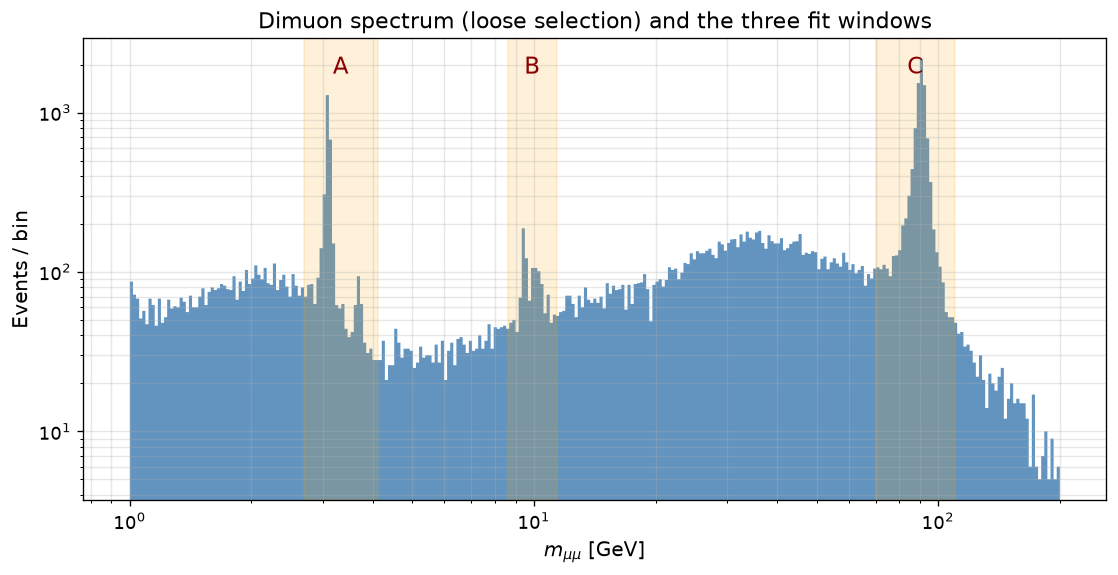

In [5]:
# the full spectrum with the three fit windows
fig, ax = plt.subplots(figsize=(11, 5))
bins_log = np.logspace(0, np.log10(200), 300)
ax.hist(m_all, bins=bins_log, color='steelblue', histtype='stepfilled', alpha=0.85)
ax.set_xscale('log'); ax.set_yscale('log')
for key, R in regions.items():
    ax.axvspan(R.lo, R.hi, alpha=0.15, color='orange')
    ax.text(np.sqrt(R.lo*R.hi), ax.get_ylim()[1]*0.6, key, ha='center', fontsize=14, color='darkred')
ax.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); ax.set_ylabel('Events / bin')
ax.set_title('Dimuon spectrum (loose selection) and the three fit windows'); ax.grid(alpha=0.3, which='both')
plt.show()

---
## 4. Maximum likelihood fits

Each region is fitted with the extended unbinned likelihood and `iminuit`: MIGRAD for the minimum, HESSE for symmetric errors, MINOS for asymmetric errors on the masses. The plots show data, fit, components and pulls
$$\text{pull}_i = \frac{n_i - \mu_i}{\sqrt{\mu_i}}$$
with $\mu_i$ the fitted expectation in bin $i$ (model integrated over the bin). For a good fit the pulls scatter around 0 with width 1.

In [6]:
# the three unbinned fits
fits = {}
for key, R in regions.items():
    t0 = time.time()
    fits[key] = R.fit(minos=tuple(f'm{k}' for k in range(R.K)))
    f = fits[key]
    v, e = f['values'], f['errors']
    print(f"=== Region {R.name}  (valid minimum: {f['valid']}, {time.time()-t0:.1f} s, -lnL = {f['fval']:.2f}) ===")
    for k in range(R.K):
        mass, dm = v[f'm{k}'], e[f'm{k}']
        print(f"  {R.peaks[k]:<8} N = {v[f'n{k}']:9.1f} +/- {e[f'n{k}']:7.1f}   mass = {mass:9.4f} +/- {dm:.4f} GeV"
              f"   (PDG {R.M[k]}, offset {1000*(mass - R.M[k]):+.1f} +/- {1000*dm:.1f} MeV)")
        try:
            me = f['m'].merrors[f'm{k}']
            if me.is_valid:
                print(f"           MINOS interval on the mass: {1000*me.lower:+.1f} / {1000*me.upper:+.1f} MeV")
        except Exception:
            pass
    print(f"  resolution sigma = {v['sig']*1000:.1f} +/- {e['sig']*1000:.1f} MeV for {R.peaks[0]} "
          f"({100*v['sig']/R.M[0]:.2f} %),  alpha = {v['alpha']:.2f},  lambda = {v['lam']:.4f}")
    print(f"  N_B = {v['nb']:.1f} +/- {e['nb']:.1f}")
    if R.use_bw:
        print(f"  natural width Gamma = {v['gam']:.3f} +/- {e['gam']:.3f} GeV (PDG {GAMMA_Z_PDG})")
    extra = [n for n in R.names if n in ('alphaR', 'fg') or n.startswith(('r', 'fs', 'fb'))]
    if extra:
        print("  " + ", ".join(f"{n} = {v[n]:.3f} +/- {e[n]:.3f}" for n in extra))
    if not f['valid']:
        print("  WARNING: MIGRAD did not converge to a valid minimum for this region")
    print()

=== Region A: J/psi, psi(2S)  (valid minimum: True, 2.4 s, -lnL = -25054.10) ===
  J/psi    N =    2379.4 +/-    83.7   mass =    3.0940 +/- 0.0008 GeV   (PDG 3.0969, offset -2.9 +/- 0.8 MeV)
           MINOS interval on the mass: -0.8 / +0.9 MeV
  psi(2S)  N =     118.4 +/-    17.6   mass =    3.6780 +/- 0.0064 GeV   (PDG 3.6861, offset -8.1 +/- 6.4 MeV)
           MINOS interval on the mass: -6.4 / +6.4 MeV
  resolution sigma = 40.3 +/- 9.7 MeV for J/psi (1.30 %),  alpha = 1.17,  lambda = 0.9976
  N_B = 1125.2 +/- 81.8
  alphaR = 1.940 +/- 0.506, fg = 0.563 +/- 0.232, rg = 0.555 +/- 0.078, r1 = 1.470 +/- 0.158, r2 = 1.824 +/- 0.105, fs0 = 0.582 +/- 0.012, fs1 = 0.159 +/- 0.014, fb0 = 0.531 +/- 0.020, fb1 = 0.178 +/- 0.022

=== Region B: Upsilon family  (valid minimum: True, 3.6 s, -lnL = -5200.28) ===
  Y(1S)    N =     245.1 +/-    21.5   mass =    9.4510 +/- 0.0084 GeV   (PDG 9.4603, offset -9.3 +/- 8.4 MeV)
           MINOS interval on the mass: -9.0 / +8.4 MeV
  Y(2S)    N =     

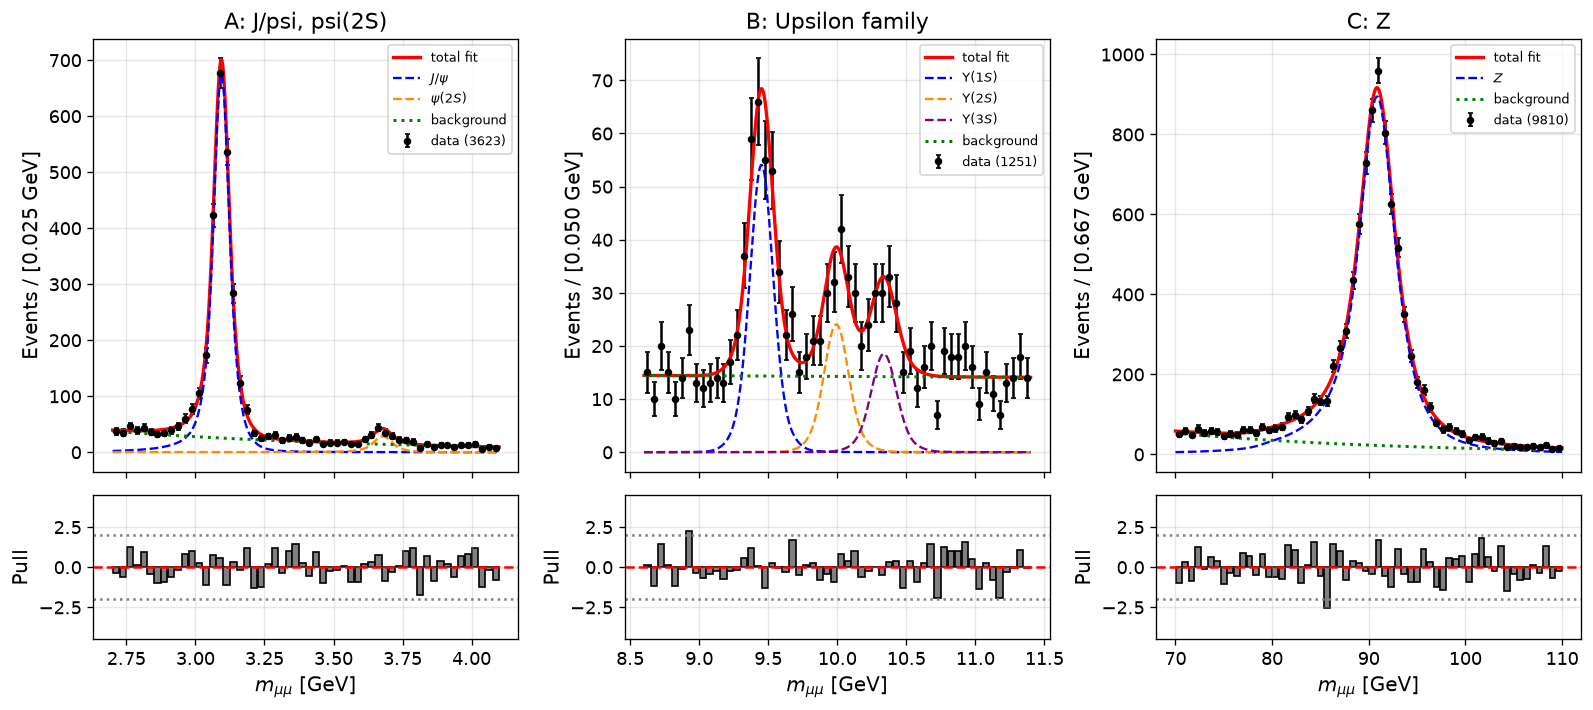

Region A: Poisson deviance = 152.5 for 168 bins and 17 parameters (ndof = 151, D/ndof = 1.01)
Region B: Poisson deviance = 172.7 for 168 bins and 17 parameters (ndof = 151, D/ndof = 1.14)
Region C: Poisson deviance = 190.0 for 180 bins and 15 parameters (ndof = 165, D/ndof = 1.15)


In [7]:
def plot_region(R, f, ax_main, ax_pull):
    p = f['values']
    scale = R.bin_width
    comps = R.components(p)
    colors = ['blue', 'darkorange', 'purple']
    tot = sum(y*fn for y, fn in comps)*scale
    ax_main.errorbar(R.bin_centers, R.counts, yerr=np.sqrt(R.counts), fmt='o', color='black', ms=3.5, capsize=1.5, label=f'data ({R.N})')
    ax_main.plot(R.xg, tot, 'r-', lw=2, label='total fit')
    
    for k in range(R.K):
        ax_main.plot(R.xg, comps[k][0]*comps[k][1]*scale, '--', color=colors[k], lw=1.4, label=PRETTY[R.peaks[k]])
    
    ax_main.plot(R.xg, comps[-1][0]*comps[-1][1]*scale, 'g:', lw=1.8, label='background')
    ax_main.set_ylabel(f'Events / [{R.bin_width:.3f} GeV]'); ax_main.set_title(R.name)
    ax_main.legend(fontsize=8); ax_main.grid(alpha=0.3)
    
    mu = R.expected_bins(p)
    pull = (R.counts - mu)/np.sqrt(mu)
    ax_pull.bar(R.bin_centers, pull, width=R.bin_width*0.9, color='gray', edgecolor='black')
    ax_pull.axhline(0, color='red', ls='--'); ax_pull.axhline(2, color='gray', ls=':'); ax_pull.axhline(-2, color='gray', ls=':')
    ax_pull.set_ylim(-4.5, 4.5); ax_pull.set_ylabel('Pull'); ax_pull.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); ax_pull.grid(alpha=0.3)
    
    return R.deviance(p)  # Poisson deviance over all categories and bins

fig = plt.figure(figsize=(16, 6.5))
gs = fig.add_gridspec(2, 3, height_ratios=[3, 1], hspace=0.08, wspace=0.25)
dev_unb = {}
for j, key in enumerate(['A', 'B', 'C']):
    ax_m = fig.add_subplot(gs[0, j]); ax_p = fig.add_subplot(gs[1, j], sharex=ax_m)
    plt.setp(ax_m.get_xticklabels(), visible=False)
    dev_unb[key] = plot_region(regions[key], fits[key], ax_m, ax_p)

plt.show()

for key, R in regions.items():
    ndof = R.ndof
    print(f"Region {key}: Poisson deviance = {dev_unb[key]:.1f} for {R.C*R.nbins} bins and {len(R.names)} parameters "
          f"(ndof = {ndof}, D/ndof = {dev_unb[key]/ndof:.2f})")

---
## 4b. Fit in the $\eta$ categories

The plot above is summed over categories. Here each category is shown on its own with its own pulls. If the categories do their job the BB peak should be clearly narrower than the EE one and the pulls should be flat in each. A pattern that was hidden in the inclusive plot, like a high-mass excess in EE only, says something about the high-mass tail.

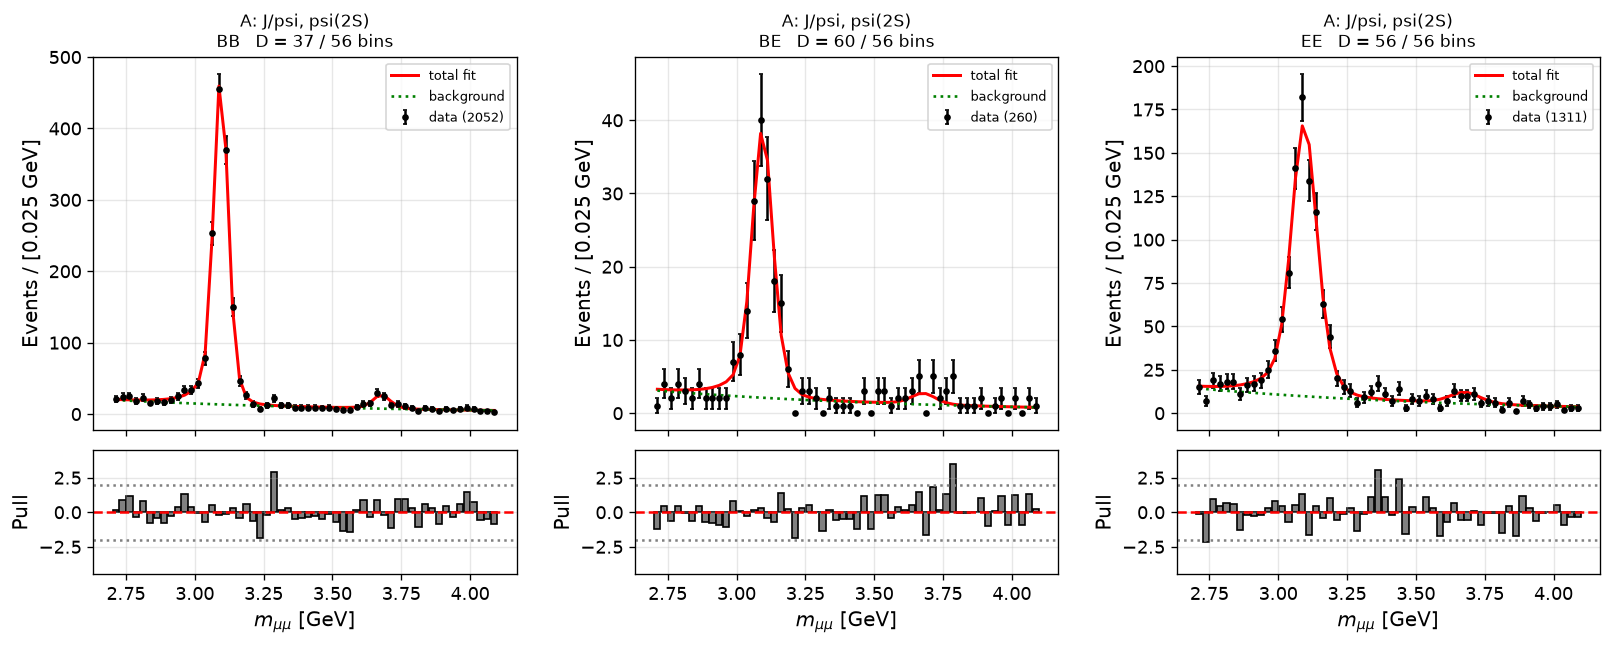

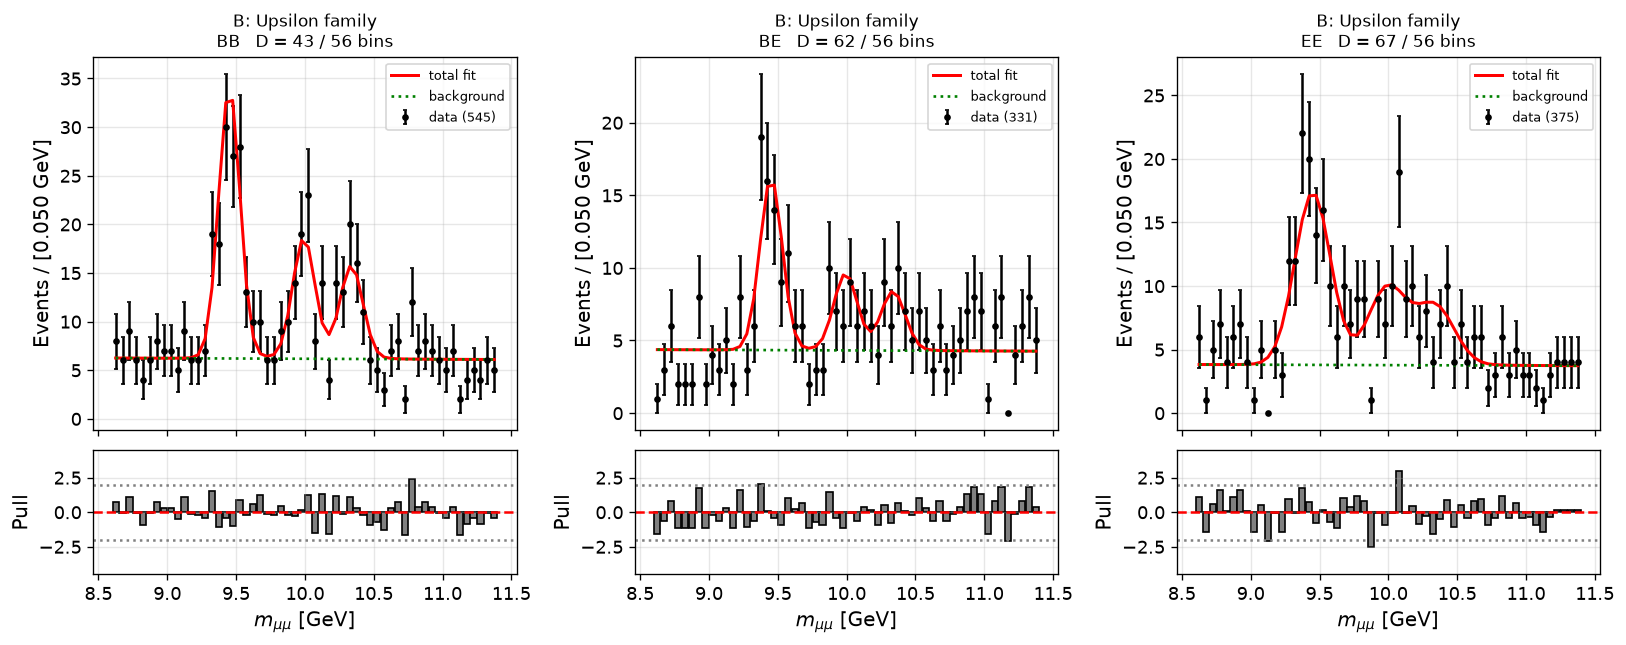

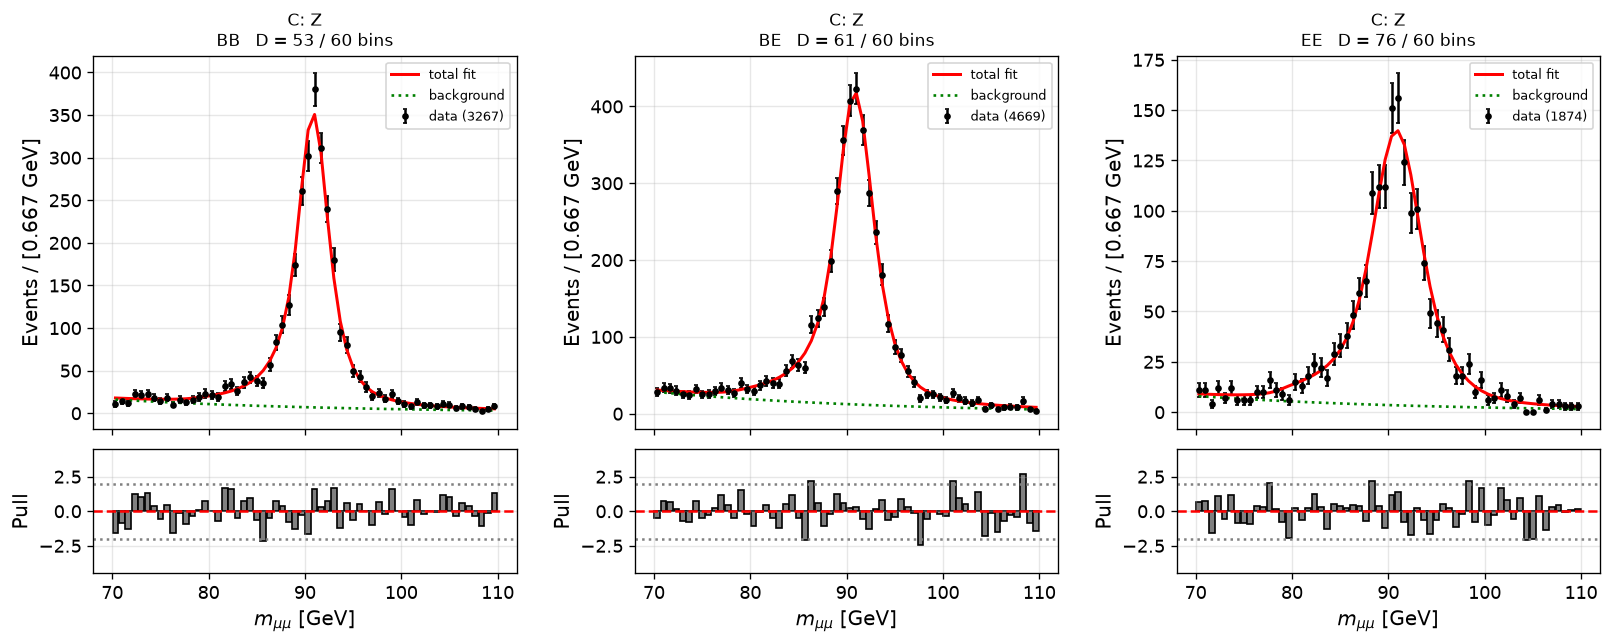

In [8]:
def plot_region_cats(R, f):
    p = f['values']
    mu_c = R.expected_bins_cat(p)
    comps = R.cat_components(p)
    fig, axes = plt.subplots(2, R.C, figsize=(5.4*R.C, 5.6), sharex='col', squeeze=False,
                             gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.08, 'wspace': 0.28})
    for c in range(R.C):
        ax, axp = axes[0, c], axes[1, c]
        n = R.counts_c[c]
        y, fr, pdf = comps[-1]
        bkg_bins = (y*fr[c]*pdf[c]*R.dx).reshape(R.nbins, R.NSUB).sum(axis=1)
        ax.errorbar(R.bin_centers, n, yerr=np.sqrt(n), fmt='o', color='black', ms=3, capsize=1.2, label=f'data ({n.sum()})')
        ax.plot(R.bin_centers, mu_c[c], 'r-', lw=1.8, label='total fit')
        ax.plot(R.bin_centers, bkg_bins, 'g:', lw=1.6, label='background')
        nz = n > 0
        dev = 2*np.sum(mu_c[c] - n) + 2*np.sum(n[nz]*np.log(n[nz]/mu_c[c][nz]))
        ax.set_title(f'{R.name}\n{R.catnames[c]}   D = {dev:.0f} / {R.nbins} bins', fontsize=10)
        ax.set_ylabel(f'Events / [{R.bin_width:.3f} GeV]'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
        plt.setp(ax.get_xticklabels(), visible=False)
        pull = (n - mu_c[c])/np.sqrt(np.maximum(mu_c[c], 1e-9))
        axp.bar(R.bin_centers, pull, width=R.bin_width*0.9, color='gray', edgecolor='black')
        for yv, ls in ((0, '--'), (2, ':'), (-2, ':')):
            axp.axhline(yv, color='red' if yv == 0 else 'gray', ls=ls)
        axp.set_ylim(-4.5, 4.5); axp.set_ylabel('Pull'); axp.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); axp.grid(alpha=0.3)
    plt.show()

for key, R in regions.items():
    plot_region_cats(R, fits[key])

---
## 4c. CB vs DCB, inclusive vs categories

Each region is refitted in four variants: {inclusive, categorised} x {CB, DCB}.

CB vs DCB with the same categorisation: the data are the same so $-\ln L$ and the AIC $=2(-\ln L)+2k$ can be compared. The CB is the limit $\alpha_R \to \infty$ of the DCB, which sits on the boundary of the parameter space, so Wilks' theorem does not apply and I use the AIC instead of $\chi^2_1$. If the DCB is only slightly better, or $\alpha_R$ runs to its upper limit, the high-mass tail is not needed.

Inclusive vs categorised: the categorised likelihood describes $(m, \text{category})$ and the inclusive one only $m$, so their $-\ln L$ cannot be compared. Instead I compare the Poisson deviance $D$ of the inclusive histogram (same bins in all variants, second to last column) and the statistical error on the mass of the main peak.

In [9]:
cmp_rows = []
schemes = ['incl'] if ETA_SCHEME == 'incl' else ['incl', ETA_SCHEME]
for key, R0 in regions.items():
    for scheme in schemes:
        for shape in ('CB', 'DCB'):
            Rv = Region(R0.name, R0.lo, R0.hi, R0.nbins, R0.peaks, list(R0.M), R0.sig_guess,
                        use_bw=R0.use_bw, cat_scheme=scheme, dcb=(shape == 'DCB'), gcore=R0.gcore)
            fv = Rv.fit()
            aic = 2*fv['fval'] + 2*len(Rv.names)
            cmp_rows.append(dict(key=key, scheme=scheme, shape=shape, npar=len(Rv.names), nll=fv['fval'], aic=aic,
                                 Dincl=Rv.deviance_incl(fv['values']), nb=Rv.nbins, valid=fv['valid'],
                                 mass=fv['values']['m0'], dmass=fv['errors']['m0'], M=Rv.M[0],
                                 aR=fv['values'].get('alphaR', np.nan)))
print("=" * 118)
print(f"{'region':<7}{'scheme':<8}{'shape':<6}{'npar':>5}{'-lnL':>13}{'dAIC(in scheme)':>17}{'D_incl':>10}{'bins':>6}"
      f"{'m0 - PDG [MeV]':>17}{'stat err [MeV]':>16}{'alphaR':>8}{'valid':>7}")
print("=" * 118)
for key in regions:
    for scheme in schemes:
        grp = [r for r in cmp_rows if r['key'] == key and r['scheme'] == scheme]
        best = min(r['aic'] for r in grp)
        for r in grp:
            print(f"{key:<7}{scheme:<8}{r['shape']:<6}{r['npar']:>5}{r['nll']:>13.2f}{r['aic'] - best:>17.1f}{r['Dincl']:>10.1f}{r['nb']:>6}"
                  f"{1000*(r['mass'] - r['M']):>17.1f}{1000*r['dmass']:>16.1f}{r['aR']:>8.2f}{str(r['valid']):>7}")
print("=" * 118)
print("dAIC is only comparable inside one (region, scheme) block. alphaR at the upper limit (5.0) = no high-mass tail needed.")

region scheme  shape  npar         -lnL  dAIC(in scheme)    D_incl  bins   m0 - PDG [MeV]  stat err [MeV]  alphaR  valid
A      incl    CB       10    -28163.87              0.4      37.4    56             -3.5             0.9     nan   True
A      incl    DCB      11    -28165.07              0.0      35.6    56             -3.4             0.9    2.08   True
A      3cat    CB       16    -25053.66              0.0      38.6    56             -2.9             0.8     nan   True
A      3cat    DCB      17    -25054.10              1.1      37.9    56             -2.9             0.8    1.94   True
B      incl    CB       10     -6537.82              0.3      44.8    56            -14.6             8.3     nan   True
B      incl    DCB      11     -6538.98              0.0      41.9    56            -16.1             8.4    1.45   True
B      3cat    CB       16     -5200.29              0.0      45.6    56             -9.1             8.4     nan   True
B      3cat    DCB      17     -

---
## 5. Discovery tests

For each peak $k$, $H_0$ is $N_k = 0$ against $H_1$: $N_k > 0$ with $m_k$ free. The test statistic is
$$q_0 = 2\left[(-\ln L_{H_0}) - (-\ln L_{\text{MLE}})\right], \qquad Z_0 \simeq \sqrt{q_0}$$
In the null fit the yield is fixed to zero, $m_k$ is put at its PDG value (it means nothing without a peak) and everything else is refitted.

Wilks' theorem only holds approximately here, since $N_k = 0$ is on the boundary and the mass only exists under $H_1$. So for the weak peaks $Z_0$ is a rough guide.

In [10]:
def nested_test(R, full, fix):
    # refit with some parameters fixed, returns q, sqrt(q), fit
    st = {k: v for k, v in full['values'].items() if k not in fix}
    f0 = R.fit(fix=fix, start=st)
    q = max(0.0, 2*(f0['fval'] - full['fval']))
    return q, np.sqrt(q), f0

def null_fix(R, k, full):
    # null fit for peak k: N_k = 0, m_k at PDG. for a one-peak region the shape parameters are frozen too
    fix = {f'n{k}': 0.0, f'm{k}': R.M[k]}
    if R.K == 1:
        for name in R.signal_shape_names:      # sig, alpha, alphaR, gam, r*, fs*
            fix[name] = full['values'][name]
    return fix

disc = {}
print("=" * 82)
print(f"{'particle':<10}{'region':<8}{'N fit':>10}{'q0':>14}{'Z0 (asympt.)':>16}{'p-value':>14}")
print("=" * 82)
for key, R in regions.items():
    for k in range(R.K):
        q, z, f0 = nested_test(R, fits[key], null_fix(R, k, fits[key]))
        p = 0.5*stats.chi2.sf(q, 1)
        disc[(key, k)] = dict(q=q, z=z, p=p)
        print(f"{R.peaks[k]:<10}{key:<8}{fits[key]['values'][f'n{k}']:>10.1f}{q:>14.1f}{z:>13.1f} sigma{p:>14.2e}")
print("=" * 82)

particle  region       N fit            q0    Z0 (asympt.)       p-value
J/psi     A           2379.4        5391.5         73.4 sigma      0.00e+00
psi(2S)   A            118.4          75.6          8.7 sigma      1.76e-18
Y(1S)     B            245.1         185.5         13.6 sigma      1.50e-42
Y(2S)     B            115.5          67.2          8.2 sigma      1.20e-16
Y(3S)     B             91.8          32.2          5.7 sigma      7.04e-09
Z         C           8269.7       13127.6        114.6 sigma      0.00e+00


---
## 6. Mass tests

Every particle has its own mass parameter $m_k$, so for each peak the test is $H_0$: $m_k = M_k^{\text{PDG}}$ against the free fit,
$$q(m_0) = 2\left[(-\ln L(m_k = m_0)) - (-\ln L_{\text{MLE}})\right], \qquad Z = \sqrt{q}$$
with all other parameters (other masses included) refitted. After that comes a profile-likelihood scan of the mass of each of the four main particles at 15 values, with the PDG and best-fit values marked. For the $Z$ the width is tested too, $H_0: \Gamma = 2.4952$ GeV.

The errors are statistical only, so a large deviation from the PDG value points to a systematic (momentum scale, line shape) and not to a real mass difference.

In [11]:
# test of m_k = PDG for every peak
mass_test = {}
print("=" * 100)
print(f"{'particle':<10}{'m fit [GeV]':>14}{'stat. error [GeV]':>20}{'offset [MeV]':>15}{'q(PDG)':>10}{'Z':>10}{'p-value':>12}")
print("=" * 100)
for key, R in regions.items():
    for k in range(R.K):
        q, z, f0 = nested_test(R, fits[key], {f'm{k}': R.M[k]})
        v, e = fits[key]['values'], fits[key]['errors']
        mass_test[(key, k)] = dict(q=q, z=z, p=stats.chi2.sf(q, 1))
        print(f"{R.peaks[k]:<10}{v[f'm{k}']:>14.4f}{e[f'm{k}']:>20.4f}{1000*(v[f'm{k}'] - R.M[k]):>15.1f}"
              f"{q:>10.1f}{z:>7.1f} sigma{stats.chi2.sf(q, 1):>12.2e}")
print("=" * 100)

# Z width test
q_w, z_w, _ = nested_test(regions['C'], fits['C'], {'gam': GAMMA_Z_PDG})
gv, ge = fits['C']['values']['gam'], fits['C']['errors']['gam']
print(f"\nZ natural width: fit {gv:.3f} +/- {ge:.3f} GeV, PDG {GAMMA_Z_PDG}:  q = {q_w:.2f}, Z = {z_w:.2f} sigma")

particle     m fit [GeV]   stat. error [GeV]   offset [MeV]    q(PDG)         Z     p-value
J/psi             3.0940              0.0008           -2.9      10.8    3.3 sigma    9.89e-04
psi(2S)           3.6780              0.0064           -8.1       1.6    1.3 sigma    2.09e-01
Y(1S)             9.4510              0.0084           -9.3       1.1    1.1 sigma    2.85e-01
Y(2S)             9.9924              0.0153          -30.9       3.0    1.7 sigma    8.44e-02
Y(3S)            10.3370              0.0173          -18.2       1.0    1.0 sigma    3.07e-01
Z                90.8610              0.0414         -326.6      27.0    5.2 sigma    2.05e-07

Z natural width: fit 2.312 +/- 0.344 GeV, PDG 2.4952:  q = 0.29, Z = 0.54 sigma


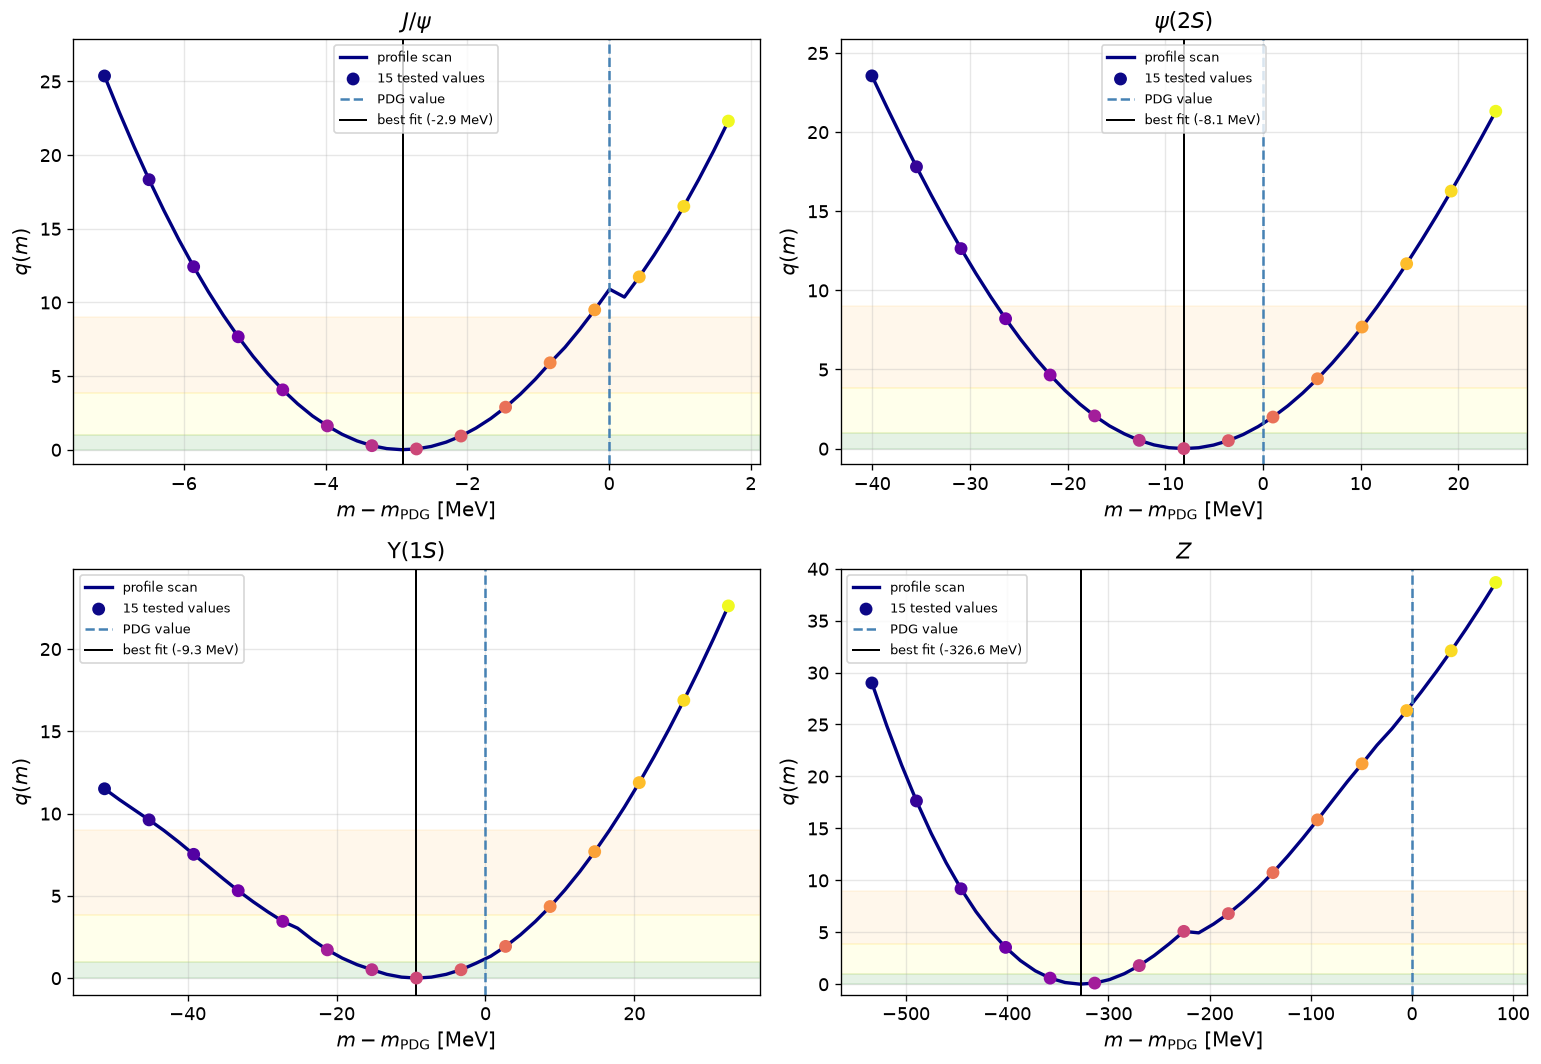

15-point scans (significance Z = sqrt(q) of excluding each mass value):

J/psi
   offset [MeV]      -7.1     -6.5     -5.9     -5.2     -4.6     -4.0     -3.3     -2.7     -2.1     -1.5     -0.8     -0.2      0.4      1.1      1.7
   Z [sigma]          5.0      4.3      3.5      2.8      2.0      1.3      0.5      0.2      1.0      1.7      2.4      3.1      3.4      4.1      4.7

psi(2S)
   offset [MeV]     -40.0    -35.5    -30.9    -26.3    -21.8    -17.2    -12.7     -8.1     -3.5      1.0      5.6     10.1     14.7     19.3     23.8
   Z [sigma]          4.9      4.2      3.6      2.9      2.2      1.4      0.7      0.0      0.7      1.4      2.1      2.8      3.4      4.0      4.6

Y(1S)
   offset [MeV]     -51.2    -45.2    -39.2    -33.2    -27.2    -21.2    -15.2     -9.3     -3.3      2.7      8.7     14.7     20.7     26.6     32.6
   Z [sigma]          3.4      3.1      2.7      2.3      1.9      1.3      0.7      0.0      0.7      1.4      2.1      2.8      3.4      4.1   

In [12]:
# profile-likelihood scan of the mass of the four main particles (15 tested values each)
scan = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (key, k) in zip(axes.ravel(), MAIN):
    R = regions[key]
    v, e = fits[key]['values'], fits[key]['errors']
    mn = f'm{k}'
    err = e[mn] if (np.isfinite(e[mn]) and e[mn] > 0) else 0.002*R.M[k]
    lo_m = min(v[mn] - 5*err, R.M[k] - 2*err)
    hi_m = max(v[mn] + 5*err, R.M[k] + 2*err)
    lo_m = max(lo_m, R.M[k]*(1 - R.mw) + 1e-6)          # stay inside the allowed mass window
    hi_m = min(hi_m, R.M[k]*(1 + R.mw) - 1e-6)
    fine = np.linspace(lo_m, hi_m, 43)                   # 43 points: every 3rd one gives the 15 tested values
    qf = np.array([nested_test(R, fits[key], {mn: x})[0] for x in fine])
    g15, q15 = fine[::3], qf[::3]
    scan[(key, k)] = (g15, q15)
    off = 1000*(fine - R.M[k])
    ax.plot(off, qf, '-', color='navy', lw=2, label='profile scan')
    ax.scatter(off[::3], q15, c=np.arange(15), cmap='plasma', s=45, zorder=5, label='15 tested values')
    ax.axhspan(0, 1, alpha=0.1, color='green'); ax.axhspan(1, 3.84, alpha=0.08, color='yellow'); ax.axhspan(3.84, 9, alpha=0.08, color='orange')
    ax.axvline(0.0, color='steelblue', ls='--', lw=1.5, label='PDG value')
    ax.axvline(1000*(v[mn] - R.M[k]), color='black', lw=1.2, label=f'best fit ({1000*(v[mn] - R.M[k]):+.1f} MeV)')
    ax.set_ylim(-1, max(12.0, min(40.0, 1.1*qf.max())))
    ax.set_xlabel(r'$m - m_{\mathrm{PDG}}$ [MeV]'); ax.set_ylabel(r'$q(m)$')
    ax.set_title(PRETTY[R.peaks[k]]); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("15-point scans (significance Z = sqrt(q) of excluding each mass value):")
for key, k in MAIN:
    R = regions[key]
    g, q = scan[(key, k)]
    print(f"\n{R.peaks[k]}")
    print("   offset [MeV]  " + " ".join(f"{1000*(x - R.M[k]):8.1f}" for x in g))
    print("   Z [sigma]     " + " ".join(f"{np.sqrt(x):8.1f}" for x in q))

### 6.1 $\Upsilon$ mass splittings ($\Delta m_{21}$, $\Delta m_{31}$)

The absolute masses depend on the muon momentum scale, which is not corrected here. If all momenta are off by a common relative amount $\delta$, every fitted mass moves as
$$m_k^{\text{fit}} \approx (1 + \delta)\, M_k^{\text{PDG}}, \qquad \Delta m_{k1}^{\text{fit}} = m_k^{\text{fit}} - m_1^{\text{fit}} \approx \Delta M_{k1}^{\text{PDG}} + \delta\,\Delta M_{k1}^{\text{PDG}}.$$
With $\Delta M_{21} \approx 0.563$ GeV and $\Delta M_{31} \approx 0.895$ GeV the splittings only move by $\delta \cdot 0.56$ GeV and $\delta \cdot 0.90$ GeV, which is about 6 % and 9 % of the shift of the $\Upsilon(1S)$ mass ($\delta \cdot 9.46$ GeV). So most of a common scale error cancels in the splittings and they are a cleaner test than the absolute masses.

For $k = 2, 3$ the test is $H_0: \Delta m_{k1} = \Delta M_{k1}^{\text{PDG}}$, done two ways:
* Gaussian error from the Minuit covariance, $\text{Var}(m_k - m_1) = \text{Var}(m_k) + \text{Var}(m_1) - 2\,\text{Cov}(m_k, m_1)$,
* profile likelihood $q(\Delta m_{k1})$, refitting with $m_k = m_1 + \Delta m_{k1}$ imposed (the `tie` option of `Region.fit`) and everything else, $m_1$ included, free.

The resolutions of the three states are tied by $\sigma_k = \sigma\, M_k/M_1$ and they share the tail parameters, so the result depends on that assumption.

splitting        fit [MeV]  cov. error   PDG [MeV]  fit-PDG [MeV]    pull  q(PDG) profile      Z
dm(2S-1S)           541.3        17.3       563.0          -21.7   -1.26            1.04   1.02
dm(3S-1S)           885.9        19.3       894.9           -9.0   -0.46            0.21   0.46


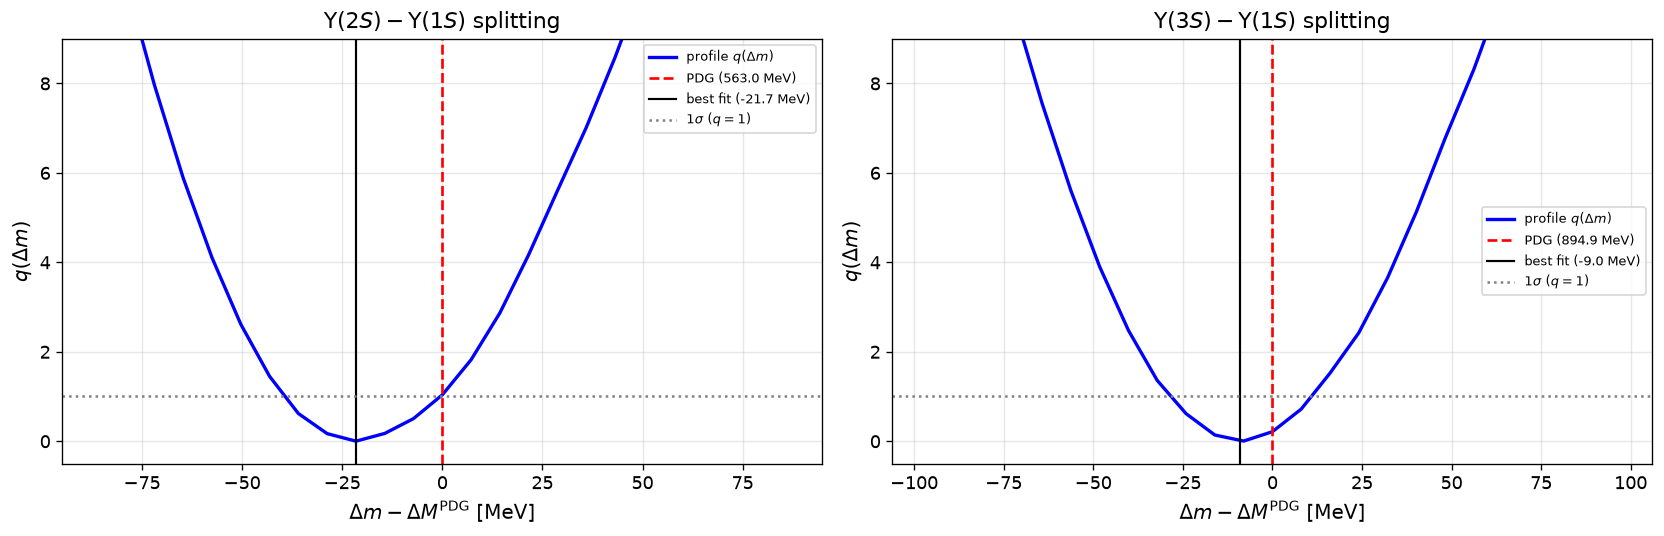

for comparison, the absolute Y(1S) mass offset is -9.3 +/- 8.4 MeV (stat), i.e. -0.098 % relative.
A common scale error delta moves the splittings by delta*dM and Y(1S) by delta*M, so for delta = 0.1 %:
  Y(1S) mass: 9.5 MeV,   dm21: 0.56 MeV,   dm31: 0.89 MeV


In [13]:
# mass splittings of the Upsilon family: covariance propagation + profile likelihood with m_k = m_1 + delta
RB, fB = regions['B'], fits['B']
vB = fB['values']
covB = fB['m'].covariance            # None if HESSE failed

def split_profile_q(k, delta):
    # q for m_k - m_0 = delta, all other parameters refitted
    st = {n: x for n, x in vB.items() if n != f'm{k}'}
    f0 = RB.fit(start=st, tie=(k, 0, delta))
    return max(0.0, 2*(f0['fval'] - fB['fval']))

split_res = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
print("=" * 96)
print(f"{'splitting':<14}{'fit [MeV]':>12}{'cov. error':>12}{'PDG [MeV]':>12}{'fit-PDG [MeV]':>15}{'pull':>8}{'q(PDG) profile':>16}{'Z':>7}")
print("=" * 96)
for ax, k in zip(axes, (1, 2)):
    d_fit, d_pdg = vB[f'm{k}'] - vB['m0'], RB.M[k] - RB.M[0]
    if covB is not None:
        err = np.sqrt(max(1e-12, covB[f'm{k}', f'm{k}'] + covB['m0', 'm0'] - 2*covB[f'm{k}', 'm0']))
    else:
        err = np.hypot(fB['errors'][f'm{k}'], fB['errors']['m0'])       # fallback: no correlation
    q_pdg = split_profile_q(k, d_pdg)
    split_res[k] = dict(fit=d_fit, err=err, pdg=d_pdg, q=q_pdg, z=np.sqrt(q_pdg))
    print(f"dm({k+1}S-1S){'':<4}{1000*d_fit:>12.1f}{1000*err:>12.1f}{1000*d_pdg:>12.1f}{1000*(d_fit - d_pdg):>15.1f}"
          f"{(d_fit - d_pdg)/err:>8.2f}{q_pdg:>16.2f}{np.sqrt(q_pdg):>7.2f}")
    half = max(5*err, 0.01)
    grid = np.linspace(d_pdg - half, d_pdg + half, 25)
    qs = np.array([split_profile_q(k, d) for d in grid])
    ax.plot(1000*(grid - d_pdg), qs, 'b-', lw=2, label=r'profile $q(\Delta m)$')
    ax.axvline(0.0, color='red', ls='--', lw=1.6, label=f'PDG ({1000*d_pdg:.1f} MeV)')
    ax.axvline(1000*(d_fit - d_pdg), color='black', lw=1.3, label=f'best fit ({1000*(d_fit - d_pdg):+.1f} MeV)')
    ax.axhline(1.0, color='gray', ls=':', label=r'$1\sigma$ ($q = 1$)')
    ax.set_ylim(-0.5, 9); ax.set_xlabel(r'$\Delta m - \Delta M^{\mathrm{PDG}}$ [MeV]'); ax.set_ylabel(r'$q(\Delta m)$')
    ax.set_title(rf'$\Upsilon({k+1}S) - \Upsilon(1S)$ splitting'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
print("=" * 96)
plt.tight_layout(); plt.show()

off1, e1 = 1000*(vB['m0'] - RB.M[0]), 1000*fB['errors']['m0']
print(f"for comparison, the absolute Y(1S) mass offset is {off1:+.1f} +/- {e1:.1f} MeV (stat), i.e. {100*(vB['m0'] - RB.M[0])/RB.M[0]:+.3f} % relative.")
print("A common scale error delta moves the splittings by delta*dM and Y(1S) by delta*M, so for delta = 0.1 %:")
print(f"  Y(1S) mass: {1000*1e-3*RB.M[0]:.1f} MeV,   dm21: {1000*1e-3*(RB.M[1]-RB.M[0]):.2f} MeV,   dm31: {1000*1e-3*(RB.M[2]-RB.M[0]):.2f} MeV")

---
## 7. Likelihood surfaces and contours

Here $-2\Delta\ln L$ is looked at as a function of two parameters, the mass of the main peak of each region ($J/\psi$, $\Upsilon(1S)$, $Z$) and the resolution $\sigma$. At every grid point all other parameters are refitted, so these are profile-likelihood contours. For two parameters the levels are $\Delta q = 2.30,\ 6.18,\ 11.83$ for $1,\ 2,\ 3\sigma$. The grid is small ($\text{GRID\_N} \times \text{GRID\_N}$) to keep the run time down.

profiled grids done in 311 s


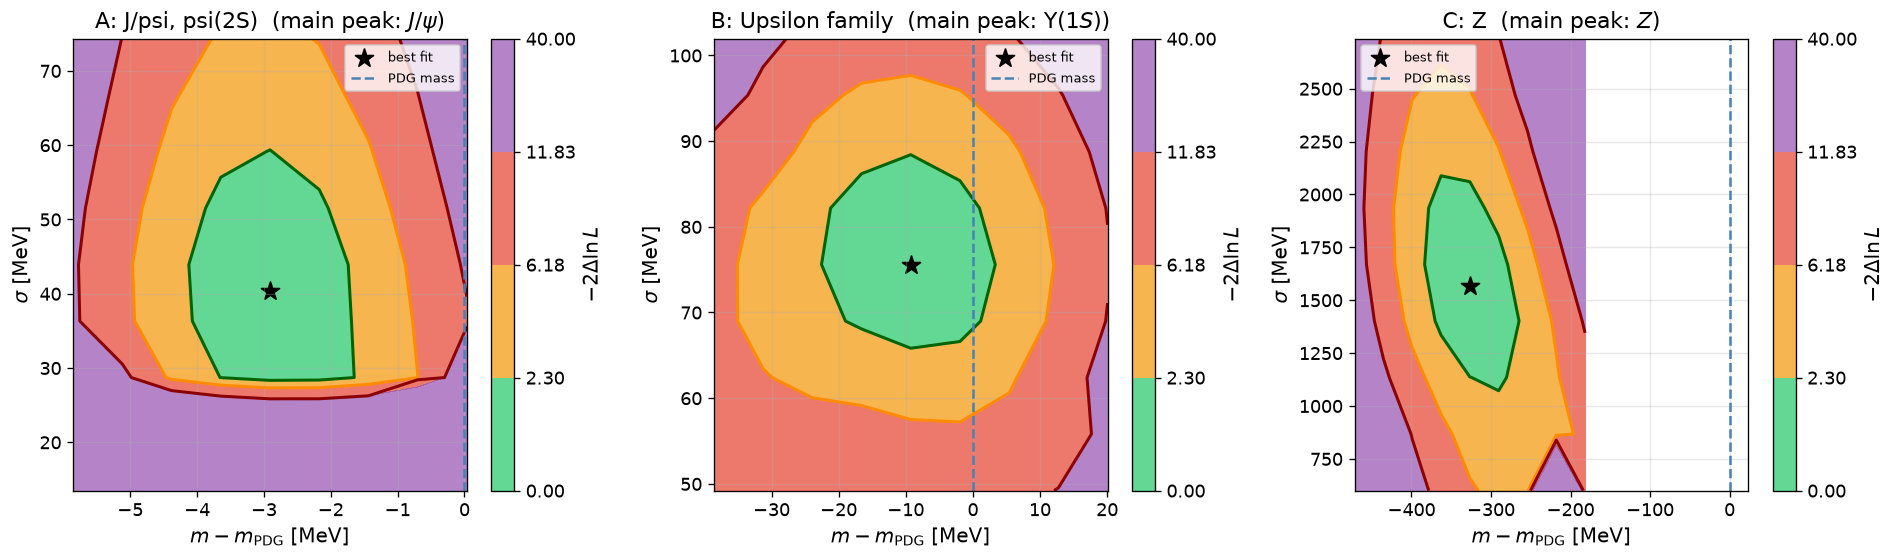

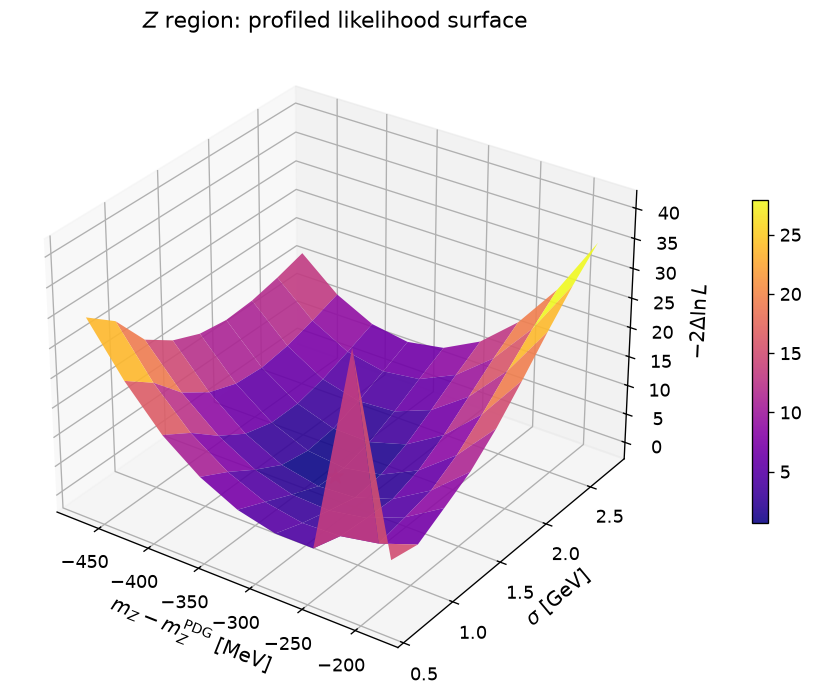

In [14]:
LV = [2.30, 6.18, 11.83]
FILL_LEVS = [0] + LV + [40]
FILL_COLS = ['#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']

grids = {}
t0 = time.time()
for key, R in regions.items():
    v, e = fits[key]['values'], fits[key]['errors']
    em = e['m0'] if (np.isfinite(e['m0']) and e['m0'] > 0) else 0.002*R.M[0]
    es = e['sig'] if (np.isfinite(e['sig']) and e['sig'] > 0) else 0.1*R.sig_guess
    mx = np.linspace(max(v['m0'] - 3.5*em, R.M[0]*(1 - R.mw) + 1e-6), min(v['m0'] + 3.5*em, R.M[0]*(1 + R.mw) - 1e-6), GRID_N)
    sy = np.linspace(max(v['sig'] - 3.5*es, 0.3*R.sig_guess), min(v['sig'] + 3.5*es, 3.9*R.sig_guess), GRID_N)
    dq = np.zeros((GRID_N, GRID_N))
    for i, y in enumerate(sy):
        for j, x in enumerate(mx):
            st = {k: val for k, val in v.items() if k not in ('m0', 'sig')}
            f = R.fit(fix={'m0': x, 'sig': y}, start=st)
            dq[i, j] = max(0.0, 2*(f['fval'] - fits[key]['fval']))
    grids[key] = (mx, sy, dq)
print(f"profiled grids done in {time.time()-t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (key, R) in zip(axes, regions.items()):
    mx, sy, dq = grids[key]
    XX, YY = np.meshgrid(1000*(mx - R.M[0]), 1000*sy)
    cf = ax.contourf(XX, YY, np.clip(dq, 0, 40), levels=FILL_LEVS, colors=FILL_COLS, alpha=0.75)
    ax.contour(XX, YY, dq, levels=LV, colors=['darkgreen', 'darkorange', 'darkred'], linewidths=1.8)
    ax.scatter(1000*(fits[key]['values']['m0'] - R.M[0]), fits[key]['values']['sig']*1000, color='black', marker='*', s=130, label='best fit')
    ax.axvline(0.0, color='steelblue', ls='--', label='PDG mass')
    ax.set_xlabel(r'$m - m_{\mathrm{PDG}}$ [MeV]'); ax.set_ylabel(r'$\sigma$ [MeV]')
    ax.set_title(f"{R.name}  (main peak: {PRETTY[R.peaks[0]]})"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.colorbar(cf, ax=ax, label=r'$-2\Delta\ln L$')
plt.tight_layout(); plt.show()

# 3D surface for the Z region
mx, sy, dq = grids['C']
XX, YY = np.meshgrid(1000*(mx - regions['C'].M[0]), sy)
fig = plt.figure(figsize=(10, 7))
ax3 = fig.add_subplot(111, projection='3d')
surf = ax3.plot_surface(XX, YY, np.clip(dq, 0, 40), cmap='plasma', alpha=0.9, linewidth=0)
ax3.scatter([1000*(fits['C']['values']['m0'] - regions['C'].M[0])], [fits['C']['values']['sig']], [0], color='red', s=90, marker='*')
ax3.set_xlabel(r'$m_Z - m_Z^{\mathrm{PDG}}$ [MeV]'); ax3.set_ylabel(r'$\sigma$ [GeV]'); ax3.set_zlabel(r'$-2\Delta\ln L$')
ax3.set_title(r'$Z$ region: profiled likelihood surface'); ax3.view_init(30, -55)
fig.colorbar(surf, ax=ax3, shrink=0.5, pad=0.1); plt.show()

---
## 8. Binned fit (cross-check)

The fits so far were unbinned. As a cross-check they are repeated on histograms with $K$ bins (56, 56 and 60 for the three regions), using only the bin contents $n_i$. The model predicts $\mu_i(\boldsymbol\theta)$ events in bin $i$ and $n_i$ is Poisson with that mean, so
$$L(\boldsymbol\theta) = \prod_{i=1}^K \frac{\mu_i^{\,n_i} e^{-\mu_i}}{n_i!}\quad\Rightarrow\quad -\ln L = \sum_{i=1}^K\big[\mu_i(\boldsymbol\theta) - n_i\ln\mu_i(\boldsymbol\theta)\big] + \text{const}$$
The constant $\sum\ln n_i!$ does not depend on the parameters. The extended term is already included because $\sum_i\mu_i = \sum_k N_k + N_B$.

$\mu_i$ is the model density integrated over the bin $[a_i,b_i]$,
$$\mu_i = \sum_k N_k\int_{a_i}^{b_i}P_k(m)\,dm + N_B\int_{a_i}^{b_i}B(m)\,dm$$
In the code (`expected_bins`) the pdfs are evaluated on a grid with 40 points per bin and summed per bin. That is better than density at the bin centre times bin width, since near the top of a narrow peak the density is far from linear across the bin.

For goodness of fit I compare with the saturated model ($\mu_i = n_i$) through the Poisson deviance
$$D = 2\sum_i\Big[\mu_i - n_i + n_i\ln\frac{n_i}{\mu_i}\Big]$$
which is roughly $\chi^2$ with $K - (\text{number of parameters})$ degrees of freedom when the counts are not too small, so $D/\text{ndof}\approx 1$ is a good fit. For the narrow $\psi(2S)$ and $\Upsilon$ peaks some bins have few counts and the $\chi^2$ approximation is rough.

The bins are narrow compared to the peaks, so the binned fit should give the same parameters as the unbinned one with slightly larger errors. The column "diff/err" is binned minus unbinned in units of the unbinned error, and values far outside $\pm 1$ would be a problem.

In [15]:
binned_fits = {}
for key, R in regions.items():
    fb = R.fit(binned=True, start=fits[key]['values'])
    binned_fits[key] = fb
    mu = R.expected_bins(fb['values'])
    dev = R.deviance(fb['values'])
    ndof = R.ndof
    pv = stats.chi2.sf(dev, ndof)
    print(f"=== Region {R.name}: binned vs unbinned ===")
    print(f"{'param':<7}{'binned':>24}{'unbinned':>26}{'diff/err':>10}")
    for k in R.names:
        vb, eb = fb['values'][k], fb['errors'][k]
        vu, eu = fits[key]['values'][k], fits[key]['errors'][k]
        d_ = (vb - vu)/eu if eu > 0 else float('nan')
        print(f"{k:<7}{vb:>12.4f} +/- {eb:<9.4f}{vu:>12.4f} +/- {eu:<9.4f}{d_:>10.2f}")
    print(f"Poisson deviance / ndof = {dev:.1f} / {ndof} = {dev/ndof:.2f}   (p = {pv:.3f})\n")

=== Region A: J/psi, psi(2S): binned vs unbinned ===
param                    binned                  unbinned  diff/err
n0        2374.8527 +/- 80.3770     2379.4429 +/- 83.7388       -0.05
n1         115.4099 +/- 17.3587      118.3576 +/- 17.5873       -0.17
nb        1132.6950 +/- 77.7485     1125.2070 +/- 81.8478        0.09
m0           3.0939 +/- 0.0009         3.0940 +/- 0.0008        -0.11
m1           3.6754 +/- 0.0065         3.6780 +/- 0.0064        -0.40
sig          0.0366 +/- 0.0096         0.0403 +/- 0.0097        -0.38
alpha        1.2543 +/- 0.4466         1.1741 +/- 0.4055         0.20
alphaR       1.9061 +/- 0.4416         1.9403 +/- 0.5064        -0.07
fg           0.4806 +/- 0.3327         0.5631 +/- 0.2316        -0.36
rg           0.5954 +/- 0.0805         0.5550 +/- 0.0784         0.52
lam          1.0026 +/- 0.1143         0.9976 +/- 0.1195         0.04
r1           1.4748 +/- 0.1562         1.4698 +/- 0.1582         0.03
r2           1.8408 +/- 0.1084         

---
## 9. Background model systematic

Everything above uses an exponential background. To see how much the masses and yields depend on that, each region is refitted with two more flexible shapes:
* exponential of a quadratic, $B(m) \propto \exp[-\lambda (m - m_{\min}) - \lambda_2 ((m - m_{\min})/W)^2]$ with $W = m_{\max} - m_{\min}$,
* Bernstein polynomials of order $n$ (`BKG_ORDERS`), $B(x) \propto \sum_{j=0}^{n} e^{a_j}\binom{n}{j} x^j (1-x)^{n-j}$ with $x = (m-m_{\min})/W$. The coefficients are written as $e^{a_j}$ (and $a_0 = 0$, since the overall scale is in $N_B$) so the density stays positive. Free-sign coefficients, e.g. Chebyshev, would not guarantee that.

Order $n$ is contained in order $n+1$, so consecutive Bernstein orders are nested with one extra parameter and $q = 2\Delta(-\ln L) \sim \chi^2_1$ can be used to pick the order. The exponential is not nested in the Bernstein family, so it is compared with the AIC.

For each alternative that converged I take the shift of every fitted mass, $\Delta m = m^{\rm alt} - m^{\rm exp}$. The largest $|\Delta m|$ is used as the background systematic and compared to the statistical error. This is more robust than one alternative shape, but it only covers the shapes I tried.

region                model               -lnL   k        AIC   D/ndof  converged  q vs exp         p
A: J/psi, psi(2S)     exp (base)      -25054.1  17   -50074.2     0.97       True                    
                      exp(quad)       -25054.2  18   -50072.4     1.00       True       0.2  6.65e-01
                      Bernstein-2     -25054.2  18   -50072.4     1.00       True         -         -
B: Upsilon family     exp (base)       -5200.3  17   -10366.6     1.17       True                    
                      exp(quad)        -5200.3  18   -10364.6     1.20       True       0.0  9.59e-01
                      Bernstein-2      -5200.3  18   -10364.6     1.20       True         -         -
C: Z                  exp (base)      -40576.7  15   -81123.3     1.19       True                    
                      exp(quad)       -40577.3  16   -81122.6     1.21       True       1.2  2.70e-01
                      Bernstein-2     -40577.3  16   -81122.6     1.20       True 

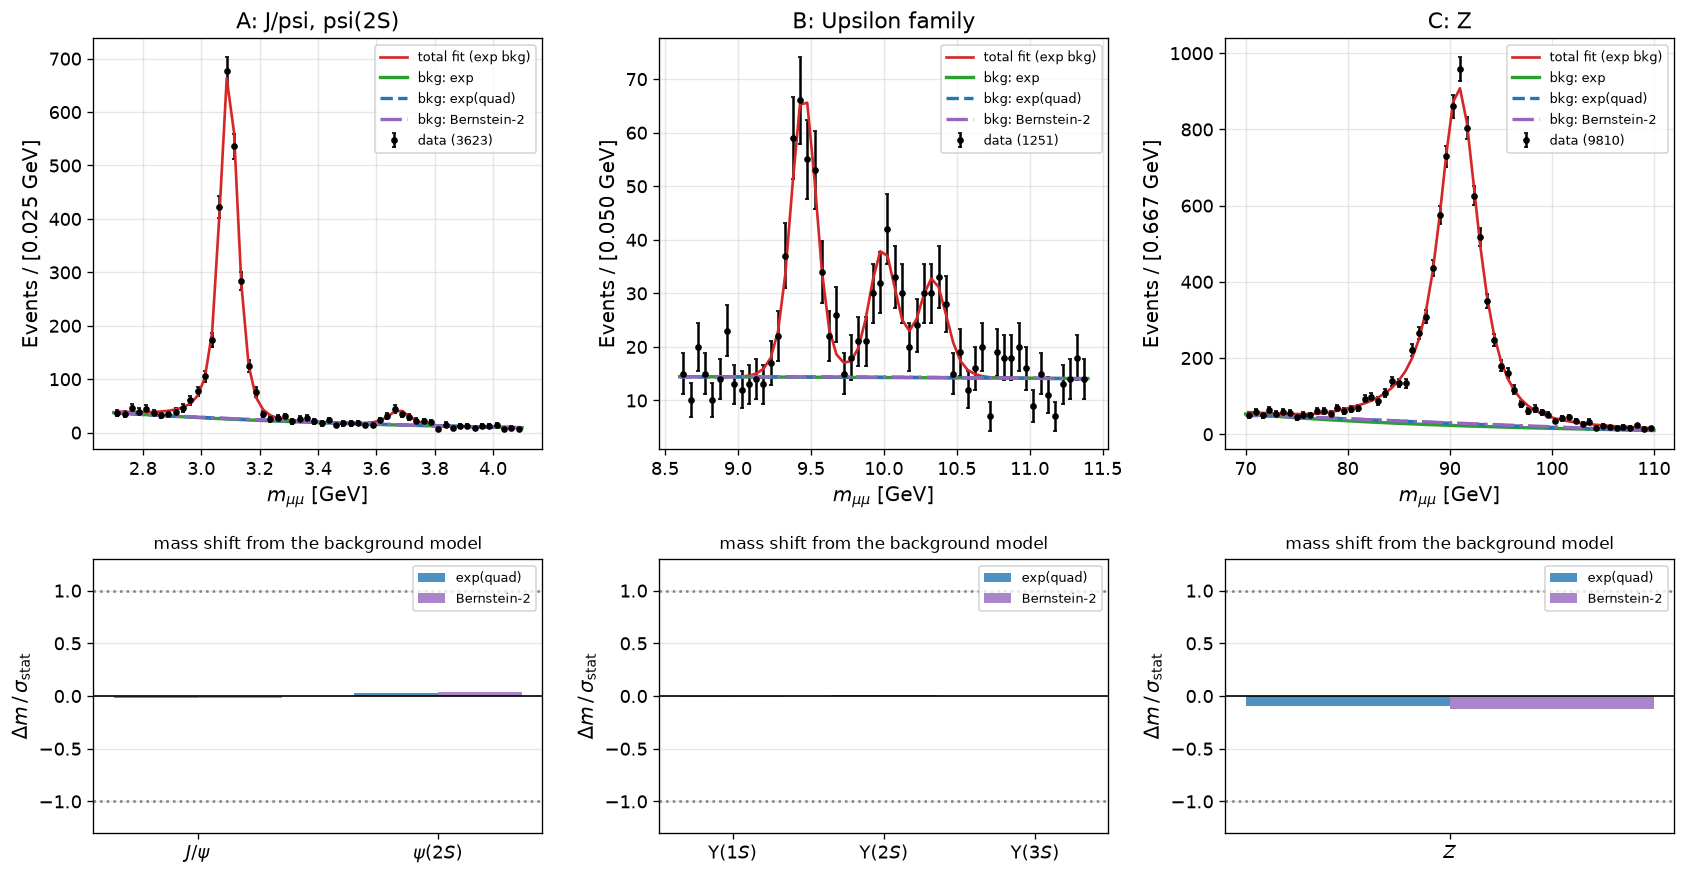

In [21]:
# ---- background-model systematic: exponential (baseline) vs exp(quadratic) vs Chebyshev-2 (Bernstein-2 for the merged Region) ----
import inspect
_R0 = next(iter(regions.values()))
V2_API = hasattr(_R0, 'use_dcb')            # v2 Region (bkg_model=...) vs merged Region (bkg=..., dcb=..., cat_scheme=...)
ALT2_LABEL = 'Chebyshev-2' if V2_API else 'Bernstein-2'
ALTS = [('quad', 'exp(quad)', 'tab:blue', '--'), ('alt2', ALT2_LABEL, 'tab:purple', '-.')]

def make_alt(R, model, label):
    args = (f"{R.name} [{label}]", R.lo, R.hi, R.nbins, R.peaks, list(R.M), R.sig_guess)
    if V2_API:
        return Region(*args, use_bw=R.use_bw, use_dcb=R.use_dcb, bkg_model='quad' if model == 'quad' else 'chebyshev')
    kw = dict(use_bw=R.use_bw, dcb=R.dcb, cat_scheme=R.cat_scheme,
              **(dict(bkg='exp2') if model == 'quad' else dict(bkg='bern', bern_order=2)))
    if 'gcore' in Region.__init__.__code__.co_varnames:
        kw['gcore'] = getattr(R, 'gcore', None)
    return Region(*args, **kw)

def poisson_dev(R, p):
    mu, n = R.expected_bins(p), R.counts
    nz = n > 0
    return 2*np.sum(mu - n) + 2*np.sum(n[nz]*np.log(n[nz]/mu[nz]))

regions_q, fits_q = {}, {}                       # quadratic alternative (kept for later cells)
alt_R, alt_f = {}, {}                            # alt_R[key][model], alt_f[key][model]
bkg_alt, bkg_syst = {}, {}                       # bkg_alt[(key,k)][model] = (dm, dN);  bkg_syst = envelope

for key, R in regions.items():
    base = fits[key]
    alt_R[key], alt_f[key] = {}, {}
    for model, label, _, _ in ALTS:
        Ra = make_alt(R, model, label)
        st = dict(base['values'])
        fix = None
        if model == 'quad':
            st['lam2'] = 0.0
        elif V2_API:                             # v2 Chebyshev carries an unused 'lam': freeze it
            st.update(c1=-0.1, c2=0.02, lam=0.0); fix = {'lam': 0.0}
        alt_R[key][model], alt_f[key][model] = Ra, Ra.fit(start=st, fix=fix)
    regions_q[key], fits_q[key] = alt_R[key]['quad'], alt_f[key]['quad']
    for k in range(R.K):
        bkg_alt[(key, k)] = {m: (alt_f[key][m]['values'][f'm{k}'] - base['values'][f'm{k}'],
                                 alt_f[key][m]['values'][f'n{k}'] - base['values'][f'n{k}']) for m, *_ in ALTS}
        worst = max(bkg_alt[(key, k)], key=lambda m: abs(bkg_alt[(key, k)][m][0]))     # envelope
        bkg_syst[(key, k)] = dict(dm=bkg_alt[(key, k)][worst][0], dN=bkg_alt[(key, k)][worst][1], model=worst)

# ---- goodness of fit and model comparison ----
print("=" * 96)
print(f"{'region':<22}{'model':<14}{'-lnL':>10}{'k':>4}{'AIC':>11}{'D/ndof':>9}{'converged':>11}{'q vs exp':>10}{'p':>10}")
print("=" * 96)
for key, R in regions.items():
    base = fits[key]
    k0 = len(R.names)
    print(f"{R.name:<22}{'exp (base)':<14}{base['fval']:>10.1f}{k0:>4}{2*base['fval'] + 2*k0:>11.1f}"
          f"{poisson_dev(R, base['values'])/(R.nbins - k0):>9.2f}{str(base['valid']):>11}{'':>10}{'':>10}")
    for model, label, _, _ in ALTS:
        Ra, fa = alt_R[key][model], alt_f[key][model]
        ka = len(Ra.names) - (1 if (V2_API and model == 'alt2') else 0)
        if model == 'quad':                                        # nested in exp (lam2 = 0): Wilks, 1 dof
            q = max(0.0, 2*(base['fval'] - fa['fval'])); qs, ps = f"{q:.1f}", f"{stats.chi2.sf(q, 1):.2e}"
        else:                                                      # not nested: compare with AIC only
            qs, ps = '-', '-'
        print(f"{'':<22}{label:<14}{fa['fval']:>10.1f}{ka:>4}{2*fa['fval'] + 2*ka:>11.1f}"
              f"{poisson_dev(Ra, fa['values'])/(Ra.nbins - ka):>9.2f}{str(fa['valid']):>11}{qs:>10}{ps:>10}")
print("=" * 96)

# ---- effect on the peak parameters; the systematic is the envelope (largest |dm|) ----
print("\nShift of the fitted mass and yield with respect to the exponential background")
print("=" * 118)
print(f"{'particle':<9}{'stat err [MeV]':>15}" + "".join(f"{lab + ' dm [MeV]':>21}{'dm/stat':>9}{'dN/N [%]':>10}" for _, lab, _, _ in ALTS)
      + f"{'syst [MeV]':>12}")
print("=" * 118)
for key, R in regions.items():
    for k in range(R.K):
        e = fits[key]['errors'][f'm{k}']; n0 = fits[key]['values'][f'n{k}']
        line = f"{R.peaks[k]:<9}{1000*e:>15.2f}"
        for model, *_ in ALTS:
            dm, dN = bkg_alt[(key, k)][model]
            line += f"{1000*dm:>21.2f}{dm/e:>9.2f}{100*dN/n0:>10.1f}"
        print(line + f"{1000*abs(bkg_syst[(key, k)]['dm']):>12.2f}")
print("=" * 118)

# ---- plots ----
fig = plt.figure(figsize=(17, 8.6))
gs = fig.add_gridspec(2, 3, height_ratios=[3, 2], hspace=0.32, wspace=0.26)
for col, (key, R) in enumerate(regions.items()):
    ax = fig.add_subplot(gs[0, col])
    ax.errorbar(R.bin_centers, R.counts, yerr=np.sqrt(R.counts), fmt='o', color='black', ms=3, capsize=1.2, label=f'data ({R.N})')
    ax.plot(R.bin_centers, R.expected_bins(fits[key]['values']), color='tab:red', lw=1.6, label='total fit (exp bkg)')
    bw = R.bin_width
    ax.plot(R.xg, fits[key]['values']['nb']*R.bkg_shape(fits[key]['values'])*bw, color='tab:green', lw=2, label='bkg: exp')
    for model, label, c, ls in ALTS:
        pa = alt_f[key][model]['values']
        ax.plot(R.xg, pa['nb']*alt_R[key][model].bkg_shape(pa)*bw, color=c, ls=ls, lw=2, label=f'bkg: {label}')
    ax.set_xlabel(r'$m_{\mu\mu}$ [GeV]'); ax.set_ylabel(f'Events / [{bw:.3f} GeV]')
    ax.set_title(R.name); ax.grid(alpha=0.3); ax.legend(fontsize=8)

    ax2 = fig.add_subplot(gs[1, col])
    x = np.arange(R.K); w = 0.35
    for j, (model, label, c, _) in enumerate(ALTS):
        pulls = [bkg_alt[(key, k)][model][0]/fits[key]['errors'][f'm{k}'] for k in range(R.K)]
        ax2.bar(x + (j - 0.5)*w, pulls, width=w, color=c, alpha=0.8, label=label)
    ax2.axhline(0, color='black', lw=1)
    for yv in (-1, 1):
        ax2.axhline(yv, color='gray', ls=':')
    ax2.set_xticks(x); ax2.set_xticklabels([PRETTY.get(p, p) for p in R.peaks])
    ax2.set_ylabel(r'$\Delta m\,/\,\sigma_{\rm stat}$'); ax2.set_title('mass shift from the background model', fontsize=10)
    ymax = max(1.3, 1.25*max(abs(bkg_alt[(key, k)][m][0]/fits[key]['errors'][f'm{k}']) for k in range(R.K) for m, *_ in ALTS))
    ax2.set_ylim(-ymax, ymax); ax2.grid(alpha=0.3, axis='y'); ax2.legend(fontsize=8)
plt.show()

---
## 10. Comparing the four particles

If the mass offsets come from a common relative momentum-scale error (not corrected here, no Rochester corrections were used), then $(m - M)/M$ should be the same at 3, 4, 9 and 91 GeV. This is tested with a $\chi^2$ for a constant, $\chi^2 = \sum_i \big((x_i - \bar x)/\delta_i\big)^2$ with $\bar x$ the weighted mean and $\text{ndof} = 3$, once with statistical errors only and once with the background systematic added in quadrature. If the offset depends on mass, something else is going on (energy loss in material, the field map, the line shape).

The relative resolution $\sigma/M$ (first category, BB by default) shows how the resolution changes with mass: multiple scattering dominates at low mass and the curvature measurement at high mass. The $J/\psi$ and $\psi(2S)$ come from one fit and share $\sigma$ and $\alpha$, so they are not fully independent.

particle               N            mass [GeV]  (stat)  (bkg syst)      PDG  offset [MeV]  sigma [MeV]  sigma/M [%]     Z0
J/psi        2379 +/-  84        3.0940 +/-0.0008 +/-0.0000   3.0969          -2.9         40.3         1.30   73.4
psi(2S)       118 +/-  18        3.6780 +/-0.0064 +/-0.0005   3.6861          -8.1         48.0         1.30    8.7
Y(1S)         245 +/-  21        9.4510 +/-0.0084 +/-0.0008   9.4603          -9.3         75.6         0.80   13.6
Y(2S)         116 +/-  16        9.9924 +/-0.0153 +/-0.0017  10.0233         -30.9         80.1         0.80    8.2
Y(3S)          92 +/-  16       10.3370 +/-0.0173 +/-0.0010  10.3552         -18.2         82.7         0.80    5.7
Z            8270 +/- 161       90.8610 +/-0.0414 +/-0.0074  91.1876        -326.6       1568.8         1.72  114.6
(the four main particles are J/psi, psi(2S), Y(1S), Z; Y(2S) and Y(3S) are the extra peaks of region B)

Common relative offset (statistical errors only): mean = -0.1604 +/- 0.0224 

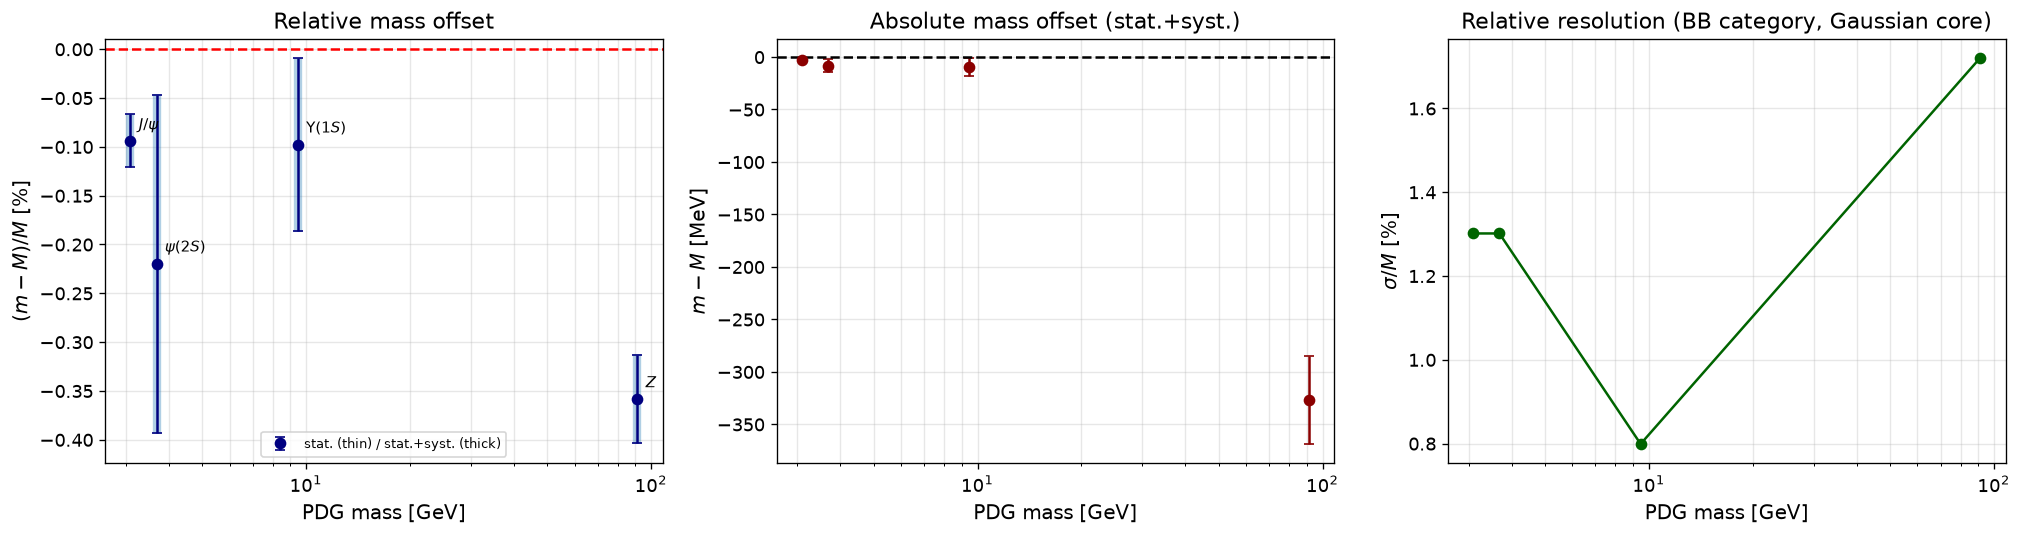

In [17]:
rows = []
for key, R in regions.items():
    v, e = fits[key]['values'], fits[key]['errors']
    for k in range(R.K):
        rows.append(dict(name=R.peaks[k], key=key, k=k, M=R.M[k], N=v[f'n{k}'], dN=e[f'n{k}'],
                         mass=v[f'm{k}'], dmass=e[f'm{k}'], dsyst=abs(bkg_syst[(key, k)]['dm']),
                         sigma=v['sig']*R.M[k]/R.M[0], z0=disc[(key, k)]['z'], q0=disc[(key, k)]['q']))

print("=" * 128)
print(f"{'particle':<9}{'N':>15}{'mass [GeV]  (stat)  (bkg syst)':>42}{'PDG':>9}{'offset [MeV]':>14}{'sigma [MeV]':>13}{'sigma/M [%]':>13}{'Z0':>7}")
print("=" * 128)
for r in rows:
    print(f"{r['name']:<9}{r['N']:>8.0f} +/-{r['dN']:>4.0f}{r['mass']:>14.4f} +/-{r['dmass']:.4f} +/-{r['dsyst']:.4f}{r['M']:>9.4f}"
          f"{1000*(r['mass'] - r['M']):>14.1f}{1000*r['sigma']:>13.1f}{100*r['sigma']/r['M']:>13.2f}{r['z0']:>7.1f}")
print("=" * 128)
print("(the four main particles are J/psi, psi(2S), Y(1S), Z; Y(2S) and Y(3S) are the extra peaks of region B)\n")

main = [r for r in rows if (r['key'], r['k']) in MAIN]

def const_test(x, dx):
    w = 1.0/dx**2
    mean = np.sum(w*x)/np.sum(w)
    chi2 = np.sum(((x - mean)/dx)**2)
    ndof = len(x) - 1
    return mean, 1.0/np.sqrt(np.sum(w)), chi2, ndof, stats.chi2.sf(chi2, ndof)

rel = np.array([(r['mass'] - r['M'])/r['M'] for r in main])
d_stat = np.array([r['dmass']/r['M'] for r in main])
d_tot = np.array([np.hypot(r['dmass'], r['dsyst'])/r['M'] for r in main])
for label, dd in (('statistical errors only', d_stat), ('stat. + background syst.', d_tot)):
    mean, dmean, chi2, ndof, pv = const_test(rel, dd)
    print(f"Common relative offset ({label}): mean = {100*mean:+.4f} +/- {100*dmean:.4f} %,  chi2/ndof = {chi2:.1f}/{ndof},  p = {pv:.3g}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
M_ = np.array([r['M'] for r in main])
ax = axes[0]
ax.errorbar(M_, 100*rel, yerr=100*d_tot, fmt='none', ecolor='tab:blue', elinewidth=5, alpha=0.35)
ax.errorbar(M_, 100*rel, yerr=100*d_stat, fmt='o', color='navy', capsize=3, label='stat. (thin) / stat.+syst. (thick)')
ax.axhline(0, color='red', ls='--'); ax.set_xscale('log')
ax.set_xlabel('PDG mass [GeV]'); ax.set_ylabel(r'$(m - M)/M$ [%]'); ax.set_title('Relative mass offset'); ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=8)
for r, x_, y_ in zip(main, M_, 100*rel):
    ax.annotate(PRETTY[r['name']], (x_, y_), textcoords='offset points', xytext=(5, 7), fontsize=9)
ax = axes[1]
ax.errorbar(M_, [1000*(r['mass'] - r['M']) for r in main], yerr=[1000*np.hypot(r['dmass'], r['dsyst']) for r in main], fmt='o', color='darkred', capsize=3)
ax.axhline(0, color='black', ls='--'); ax.set_xscale('log')
ax.set_xlabel('PDG mass [GeV]'); ax.set_ylabel(r'$m - M$ [MeV]'); ax.set_title('Absolute mass offset (stat.+syst.)'); ax.grid(alpha=0.3, which='both')
ax = axes[2]
ax.plot(M_, [100*r['sigma']/r['M'] for r in main], 'o-', color='darkgreen')
ax.set_xscale('log'); ax.set_xlabel('PDG mass [GeV]'); ax.set_ylabel(r'$\sigma / M$ [%]')
ax.set_title(f'Relative resolution ({CAT_NAMES[0]} category, Gaussian core)'); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

---
## 11. Summary

In [18]:
print("=" * 100)
print("SUMMARY")
print("=" * 100)
print("\nYields and masses:")
for r in main:
    print(f"  {r['name']:<8} N = {r['N']:.0f} +/- {r['dN']:.0f},  mass = {r['mass']:.4f} +/- {r['dmass']:.4f} (stat) +/- {r['dsyst']:.4f} (bkg) GeV   (PDG {r['M']})")

def strength(z):
    return '>= 5 sigma' if z >= 5 else ('>= 3 sigma' if z >= 3 else '< 3 sigma')

print("\nDiscovery (H0: N = 0):")
for r in main:
    print(f"  {r['name']:<8} Z0 = {r['z0']:.1f} sigma (asymptotic) -> {strength(r['z0'])}")

print("\nMass test (H0: m = PDG):")
for r in main:
    zm = mass_test[(r['key'], r['k'])]['z']
    off, st_, sy_ = 1000*(r['mass'] - r['M']), 1000*r['dmass'], 1000*r['dsyst']
    verdict = 'compatible with PDG' if zm < 2 else 'not compatible with PDG (systematic)'
    print(f"  {r['name']:<8} offset = {off:+.1f} +/- {st_:.1f} (stat) +/- {sy_:.1f} (bkg) MeV,  Z = {zm:.1f} sigma -> {verdict}")

print(f"\nZ width: {gv:.3f} +/- {ge:.3f} GeV (PDG {GAMMA_Z_PDG}),  Z(Gamma = PDG) = {z_w:.1f} sigma")
print("\nUpsilon mass splittings (H0: splitting = PDG, profile likelihood):")
for k, nm in ((1, 'dm(2S-1S)'), (2, 'dm(3S-1S)')):
    s_ = split_res[k]
    print(f"  {nm:<10} = {1000*s_['fit']:.1f} +/- {1000*s_['err']:.1f} MeV (PDG {1000*s_['pdg']:.1f}),  fit - PDG = {1000*(s_['fit'] - s_['pdg']):+.1f} MeV,  Z = {s_['z']:.2f} sigma")
mean, dmean, chi2, ndof, pv = const_test(rel, d_tot)
print(f"Common relative mass offset: {100*mean:+.4f} +/- {100*dmean:.4f} %,  chi2/ndof = {chi2:.1f}/{ndof} (p = {pv:.3g})")
for key, R in regions.items():
    print(f"Goodness of fit region {key}: D/ndof = {dev_unb[key]/(R.ndof):.2f}")
print("=" * 100)

SUMMARY

Yields and masses:
  J/psi    N = 2379 +/- 84,  mass = 3.0940 +/- 0.0008 (stat) +/- 0.0000 (bkg) GeV   (PDG 3.0969)
  psi(2S)  N = 118 +/- 18,  mass = 3.6780 +/- 0.0064 (stat) +/- 0.0005 (bkg) GeV   (PDG 3.6861)
  Y(1S)    N = 245 +/- 21,  mass = 9.4510 +/- 0.0084 (stat) +/- 0.0008 (bkg) GeV   (PDG 9.4603)
  Z        N = 8270 +/- 161,  mass = 90.8610 +/- 0.0414 (stat) +/- 0.0074 (bkg) GeV   (PDG 91.1876)

Discovery (H0: N = 0):
  J/psi    Z0 = 73.4 sigma (asymptotic) -> >= 5 sigma
  psi(2S)  Z0 = 8.7 sigma (asymptotic) -> >= 5 sigma
  Y(1S)    Z0 = 13.6 sigma (asymptotic) -> >= 5 sigma
  Z        Z0 = 114.6 sigma (asymptotic) -> >= 5 sigma

Mass test (H0: m = PDG):
  J/psi    offset = -2.9 +/- 0.8 (stat) +/- 0.0 (bkg) MeV,  Z = 3.3 sigma -> not compatible with PDG (systematic)
  psi(2S)  offset = -8.1 +/- 6.4 (stat) +/- 0.5 (bkg) MeV,  Z = 1.3 sigma -> compatible with PDG
  Y(1S)    offset = -9.3 +/- 8.4 (stat) +/- 0.8 (bkg) MeV,  Z = 1.1 sigma -> compatible with PDG
  Z      